In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [3]:
from pathlib import Path
from contextlib import ExitStack
import os
import time
import uuid
import rasterio
from affine import Affine
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.windows import Window, from_bounds, bounds
from rasterio.warp import reproject
import numpy as np
import xarray as xr

ERA5_DIR = Path(
    "/exports/geos.ed.ac.uk/gcel/spatial_datasets/"
    "meteorology/ERA5/global_0.1deg"
)
OUTPUT = Path("../../scratch/climate_site_selection/era5_luke_winter_climatology_with_canopy.nc")

VARIABLES = {  # Output name: (input filename prefix, input variable).
    "air_temperature_mean": ("airt_daily_mean", "airt_mean"),
    "air_temperature_min": ("airt_daily_min", "airt_min"),
    "air_temperature_max": ("airt_daily_max", "airt_max"),
    "precipitation_mean": ("precipitation_daily_mean", "daily_precip"),
    "wind_speed_mean": ("wind_spd_daily_mean", "wind_spd"),
    "vpd_mean": ("vpd_daily_mean", "vpd_mean"),
    "sw_radiation_mean": ("sw_radiation_daily_mean", "daily_swrad"),
}

WINTERS = list(range(2018, 2024))
PERIODS = ["OND", "JFM"]

TCC_DIR = Path("../../scratch/climate_site_selection/tcc/")
MIN_CANOPY_COVERAGE = 0.90
MIN_TEMPORAL_COVERAGE = 0.90  # Required separately in every winter-period.
SNOW_DAY_THRESHOLD = 0.1  # kg m-2 day-1; diagnostic threshold, not a selection filter.

# One notebook cell; dependencies: numpy, xarray, dask, netCDF4, rasterio, affine.
# Daily-derived RH and snowfall retain the supplied script's approximations.
# if OUTPUT.exists():
#     raise FileExistsError(f"Choose a new OUTPUT filename; already exists: {OUTPUT}")
tiles = sorted(TCC_DIR.glob("*_tcc_2020.tif"))
if not tiles:
    raise FileNotFoundError(f"No *_tcc_2020.tif files found in {TCC_DIR}")
started = time.perf_counter()
totals = None
minimum_coverage = None
source_attrs = {}
expected_days = 0

for year in range(min(WINTERS), max(WINTERS) + 2):
    print(f"Reading daily fields for {year}", flush=True)
    annual_started = time.perf_counter()

    with ExitStack() as stack:  # Keep this year's input files open during computation.
        daily_fields = {}

        for output_name, (prefix, variable) in VARIABLES.items():
            path = ERA5_DIR / f"{prefix}_{year}.nc"
            ds = stack.enter_context(
                xr.open_dataset(path, chunks={})  # Respect the stored chunk sizes.
            )

            lat = ds["lat"]
            lon = ds["lon"]

            if "long_dim" in lat.dims:
                lat = lat.isel(long_dim=0, drop=True)
            if "lat_dim" in lon.dims:
                lon = lon.isel(lat_dim=0, drop=True)

            lat_attrs = dict(lat.attrs)
            lon_attrs = dict(lon.attrs)

            da = ds[variable]
            extra = [
                d for d in da.dims
                if d not in ("doy", "lat_dim", "long_dim")
            ]
            if extra:
                da = da.squeeze(extra, drop=True)

            da = da.transpose("doy", "lat_dim", "long_dim")

            doy = ds["doy"]
            if np.issubdtype(doy.dtype, np.number):
                origin = 0 if doy.values.min() == 0 else 1
                offsets = doy.values.astype(int) - origin
                dates = (
                    np.datetime64(f"{year}-01-01", "ns")
                    + offsets.astype("timedelta64[D]")
                )
            else:
                dates = doy.values

            daily_fields[output_name] = xr.DataArray(
                da.data,  # Retain lazy loading of the daily data.
                dims=("time", "latitude", "longitude"),
                coords={
                    "time": dates,
                    "latitude": lat.values,
                    "longitude": lon.values,
                },
                attrs={
                    **da.attrs,
                    "source_variable": variable,
                    "source_files": f"{prefix}_YYYY.nc",
                },
            ).sortby("time")

        daily = xr.merge(
            [da.to_dataset(name=name) for name, da in daily_fields.items()],
            join="exact",  # Require matching dates and grids across variables.
        )

        for j, (winter, start, end) in enumerate([
            (year, f"{year}-10-01", f"{year}-12-31"),
            (year - 1, f"{year}-01-01", f"{year}-03-31"),
        ]):
            if winter not in WINTERS:
                continue

            subset = daily.sel(time=slice(start, end)).copy()

            expected = np.arange(np.datetime64(start), np.datetime64(end) + 1,
                                 dtype="datetime64[D]")
            actual = subset.time.values.astype("datetime64[D]")
            if not np.array_equal(actual, expected):
                raise ValueError(f"Missing or duplicate dates in {start} to {end}")
            expected_days += len(expected)

            tmean = subset["air_temperature_mean"] - 273.15  # Kelvin to Celsius.
            tmin = subset["air_temperature_min"] - 273.15
            tmax = subset["air_temperature_max"] - 273.15

            es_min = 610.8 * np.exp(17.27 * tmin / (tmin + 237.3))  # Pa, over water.
            es_max = 610.8 * np.exp(17.27 * tmax / (tmax + 237.3))
            es = (es_min + es_max) / 2  # FAO-56 approximation to daily saturation pressure.
            ea = es - subset["vpd_mean"]  # Estimate daily actual vapour pressure, in Pa.

            subset["relative_humidity_mean"] = (
                100 * ea / es
            ).clip(min=0, max=100)  # Bound the daily RH approximation to 0–100%.

            subset["relative_humidity_mean"].attrs = {
                "long_name": "Estimated daily relative humidity",
                "units": "%",
                "method": (
                    "FAO-56: es = (es(Tmin) + es(Tmax))/2; "
                    "ea = es - VPD; RH = 100*ea/es; bounded to 0–100 percent"
                ),
                "assumption": (
                    "Daily VPD is treated as daily mean saturation pressure "
                    "minus daily mean actual vapour pressure"
                ),
                "limitation": (
                    "Daily saturation pressure and RH are approximations; "
                    "the source VPD processing definition has not been verified"
                ),
                "reference": "Allen et al. (1998), FAO Irrigation and Drainage Paper 56",
            }

            snow_fraction = (
                -0.482292
                * (np.tanh(0.7205 * (tmean - 1.1662)) - 1.0223)
            ).clip(min=0, max=1)  # Dai (2008) annual land coefficients; fraction, not percent.

            snow_fraction = xr.where(
                tmean <= -10, 1.0,
                xr.where(tmean >= 10, 0.0, snow_fraction),
            ).where(tmean.notnull())  # Use all-snow/all-rain limits outside the fitted range.

            precipitation = subset["precipitation_mean"].clip(min=0)
            subset["snowfall_mean"] = precipitation * snow_fraction

            subset["snowfall_mean"].attrs = {
                "long_name": "Estimated daily snowfall water equivalent",
                "units": "kg m-2 day-1",
                "method": (
                    "Daily precipitation multiplied by the Dai (2008) "
                    "temperature-based conditional snow fraction"
                ),
                "snow_fraction_equation": (
                    "clip(-0.482292*(tanh(0.7205*(T_C-1.1662))-1.0223),0,1); "
                    "all snow at T_C <= -10; all rain at T_C >= 10"
                ),
                "limitation": (
                    "Applied to daily mean temperature; does not resolve "
                    "temperature during precipitation or intraday phase changes"
                ),
                "reference": "Dai (2008), doi:10.1029/2008GL033295",
            }

            subset["above_freezing_day_fraction"] = (tmax > 0).where(tmax.notnull())
            subset["freeze_thaw_day_fraction"] = ((tmin < 0) & (tmax > 0)).where(
                tmin.notnull() & tmax.notnull()
            )
            subset["snowfall_day_fraction"] = (
                subset["snowfall_mean"] >= SNOW_DAY_THRESHOLD
            ).where(subset["snowfall_mean"].notnull())
            subset["relative_humidity_clipped_day_fraction"] = (
                ((100 * ea / es) < 0) | ((100 * ea / es) > 100)
            ).where(np.isfinite(ea) & np.isfinite(es))
            for name in list(subset.data_vars):
                subset[name] = subset[name].where(np.isfinite(subset[name]))
            for name in subset.data_vars:
                source_attrs[name] = dict(subset[name].attrs)

            stats = xr.Dataset()
            for name, da in subset.data_vars.items():
                # Centre temperatures before squaring to improve numerical precision.
                offset = 273.15 if name.startswith("air_temperature_") else 0.0
                values = da.astype("float64") - offset
                stats[name + "__sum"] = values.sum("time", skipna=True)
                stats[name + "__count"] = values.count("time")
                if not name.endswith("_fraction"):
                    stats[name + "__sumsq"] = (values * values).sum("time", skipna=True)
            stats = stats.compute(scheduler="single-threaded")
            counts = xr.Dataset({
                name: stats[name + "__count"] / len(expected)
                for name in subset.data_vars
            })
            minimum_coverage = counts if minimum_coverage is None else xr.apply_ufunc(
                np.minimum, minimum_coverage, counts, join="exact"
            )
            if totals is None:
                totals = stats
            else:
                totals, stats = xr.align(totals, stats, join="exact")
                totals = totals + stats
            print(f"  Aggregated {winter}/{str(winter + 1)[-2:]} {PERIODS[j]} "
                  f"({len(expected)} days)", flush=True)
            del subset, stats, counts
    print(f"Finished {year} in {(time.perf_counter() - annual_started)/60:.1f} minutes",
          flush=True)

result = xr.Dataset()
for name, attrs in source_attrs.items():
    count = totals[name + "__count"]
    denominator = count.where(count > 0)
    centered_mean = totals[name + "__sum"] / denominator
    offset = 273.15 if name.startswith("air_temperature_") else 0.0
    result[name] = (centered_mean + offset).astype("float32")
    result[name].attrs = {**attrs, "long_name": name.replace("_", " "),
                          "cell_methods": "time: mean"}
    if name.endswith("_fraction"):
        result[name].attrs["units"] = "1"
    else:
        sd_name = name.removesuffix("_mean") + "_daily_sd"
        variance = (totals[name + "__sumsq"] / denominator - centered_mean**2).clip(min=0)
        result[sd_name] = np.sqrt(variance).astype("float32")
        result[sd_name].attrs = {
            "long_name": f"Population standard deviation of daily {name}",
            "units": attrs.get("units", "unknown"),
            "cell_methods": "time: standard_deviation",
            "description": "Pooled across all selected days, including seasonal and interannual variation",
        }
    result[name + "_valid_day_count"] = count.astype("int32")
    result[name + "_min_period_valid_fraction"] = minimum_coverage[name].astype("float32")
    result[name + "_min_period_valid_fraction"].attrs["units"] = "1"

result["above_freezing_day_fraction"].attrs["definition"] = "Daily Tmax > 0 degrees Celsius"
result["freeze_thaw_day_fraction"].attrs["definition"] = "Daily Tmin < 0 and Tmax > 0 degrees Celsius; air-temperature proxy"
result["snowfall_day_fraction"].attrs["threshold_kg_m2_day"] = SNOW_DAY_THRESHOLD
result["relative_humidity_clipped_day_fraction"].attrs["definition"] = "Fraction of valid days with estimated RH outside 0 to 100 before clipping"
result["latitude"].attrs = {"standard_name": "latitude", "units": "degrees_north"}
result["longitude"].attrs = {"standard_name": "longitude", "units": "degrees_east"}
del totals, minimum_coverage

original_lat = result.latitude.values
original_lon = result.longitude.values
lat_order = np.argsort(original_lat)[::-1]  # Raster calculations require north-to-south rows.
wrapped_lon = (original_lon + 180) % 360 - 180
lon_order = np.argsort(wrapped_lon)  # Also support NetCDF longitudes stored as 0–360.
lat = original_lat[lat_order]
lon = wrapped_lon[lon_order]

dy = float(np.median(-np.diff(lat)))
dx = float(np.median(np.diff(lon)))

if not (
    np.allclose(-np.diff(lat), dy)
    and np.allclose(np.diff(lon), dx)
    and dx > 0 and dy > 0
):
    raise ValueError("Expected a regular latitude/longitude grid without duplicate longitudes")

west, east = float(lon[0] - dx / 2), float(lon[-1] + dx / 2)
south, north = float(lat[-1] - dy / 2), float(lat[0] + dy / 2)
transform = from_origin(west, north, dx, dy)

shape = (len(lat), len(lon))
weighted = np.zeros(shape, dtype="float64")
covered = np.zeros(shape, dtype="float64")
used = 0

for path in tiles:
    with rasterio.open(path) as src:
        if src.crs is None or src.crs.to_epsg() != 4326 or src.count != 1:
            raise ValueError(f"Expected a one-band EPSG:4326 canopy tile: {path}")

        left = max(west, src.bounds.left)
        right = min(east, src.bounds.right)
        bottom = max(south, src.bounds.bottom)
        top = min(north, src.bounds.top)

        if left >= right or bottom >= top:
            continue

        used += 1
        raw = from_bounds(left, bottom, right, top, transform=src.transform)
        col0 = max(0, int(np.floor(raw.col_off)))
        row0 = max(0, int(np.floor(raw.row_off)))
        col1 = min(src.width, int(np.ceil(raw.col_off + raw.width)))
        row1 = min(src.height, int(np.ceil(raw.row_off + raw.height)))

        pad_x = int(np.ceil(dx / abs(src.res[0]))) + 2
        pad_y = int(np.ceil(dy / abs(src.res[1]))) + 2

        for row in range(row0, row1, 4096):
            for col in range(col0, col1, 4096):
                window = Window(
                    col, row,
                    min(4096, col1 - col),
                    min(4096, row1 - row),
                )
                values = src.read(1, window=window, masked=True)
                data = values.astype("float32").filled(255)
                valid = (
                    ~np.ma.getmaskarray(values)
                    & np.isfinite(data)
                    & (data >= 0)
                    & (data <= 100)
                )
                if not valid.any():
                    continue

                # Restrict each warp to the small part of the NetCDF grid it touches.
                block_left, block_bottom, block_right, block_top = bounds(
                    window, src.transform
                )
                target = from_bounds(
                    block_left, block_bottom, block_right, block_top,
                    transform=transform,
                )
                r0 = max(0, int(np.floor(target.row_off)))
                c0 = max(0, int(np.floor(target.col_off)))
                r1 = min(len(lat), int(np.ceil(target.row_off + target.height)))
                c1 = min(len(lon), int(np.ceil(target.col_off + target.width)))

                if r0 >= r1 or c0 >= c1:
                    continue

                # Padding ensures partial contributions at source-block edges are retained.
                source_transform = (
                    src.window_transform(window)
                    * Affine.translation(-pad_x, -pad_y)
                )
                data = np.pad(
                    np.where(valid, data, 255),
                    ((pad_y, pad_y), (pad_x, pad_x)),
                    constant_values=255,
                )
                mask = np.pad(
                    valid.astype("float32"),
                    ((pad_y, pad_y), (pad_x, pad_x)),
                )

                block_shape = (r1 - r0, c1 - c0)
                destination_transform = transform * Affine.translation(c0, r0)
                mean = np.full(block_shape, np.nan, dtype="float32")
                fraction = np.zeros(block_shape, dtype="float32")

                reproject(
                    data, mean,
                    src_transform=source_transform,
                    src_crs=src.crs,
                    src_nodata=255,
                    dst_transform=destination_transform,
                    dst_crs="EPSG:4326",
                    dst_nodata=np.nan,
                    resampling=Resampling.average,
                )
                reproject(
                    mask, fraction,
                    src_transform=source_transform,
                    src_crs=src.crs,
                    dst_transform=destination_transform,
                    dst_crs="EPSG:4326",
                    dst_nodata=0,
                    resampling=Resampling.average,
                )  # Zero mask values must participate in the coverage average.

                fraction = np.clip(fraction, 0, 1)
                weighted[r0:r1, c0:c1] += np.nan_to_num(mean) * fraction
                covered[r0:r1, c0:c1] += fraction

    print(f"Aggregated {path.name}", flush=True)

if used == 0:
    raise ValueError("None of the cached canopy tiles overlaps the NetCDF grid")

canopy = np.full(shape, np.nan, dtype="float32")
np.divide(weighted, covered, out=canopy, where=covered > 0)
if np.any(covered > 1.01):
    raise ValueError("Canopy coverage exceeds 1: check for overlapping or duplicate tiles")
coverage = np.clip(covered, 0, 1).astype("float32")

restore_lat = np.argsort(lat_order)  # Restore the NetCDF's original coordinate ordering.
restore_lon = np.argsort(lon_order)
canopy = canopy[np.ix_(restore_lat, restore_lon)]
coverage = coverage[np.ix_(restore_lat, restore_lon)]

result["tree_canopy_cover_2020"] = (("latitude", "longitude"), canopy)
result["tree_canopy_coverage_fraction"] = (("latitude", "longitude"), coverage)
result["tree_canopy_cover_2020"].attrs = {
    "units": "%", "long_name": "Mean valid NASA ABoVE tree canopy cover, 2020",
    "source": "NASA ABoVE, doi:10.3334/ORNLDAAC/2012",
    "aggregation": "Valid-pixel mean with angular grid-cell overlap weights",
}
result["tree_canopy_coverage_fraction"].attrs = {
    "units": "1", "long_name": "Approximate valid canopy fraction of grid cell"
}
core = ["air_temperature_mean", "snowfall_mean", "relative_humidity_mean", "wind_speed_mean"]
eligible = (result.tree_canopy_coverage_fraction >= MIN_CANOPY_COVERAGE)
eligible &= np.isfinite(result.tree_canopy_cover_2020) & (result.tree_canopy_cover_2020 > 0)
for name in core:
    eligible &= np.isfinite(result[name])
    eligible &= result[name + "_min_period_valid_fraction"] >= MIN_TEMPORAL_COVERAGE
result["eligible_cell"] = eligible.astype("int8")
result["eligible_cell"].attrs = {
    "long_name": "Candidate cell for later study-area screening",
    "minimum_canopy_coverage": MIN_CANOPY_COVERAGE,
    "minimum_valid_fraction_each_winter_period": MIN_TEMPORAL_COVERAGE,
    "description": "Nonzero canopy and valid climate; no minimum snowfall imposed",
}
cc = result.tree_canopy_cover_2020
band = xr.where((cc > 0) & (cc < 25), 1,
                xr.where((cc >= 25) & (cc <= 50), 2, xr.where(cc > 50, 3, 0)))
result["canopy_band"] = band.astype("int8")
result["canopy_band"].attrs = {
    "flag_values": np.array([0, 1, 2, 3], dtype="int8"),
    "flag_meanings": "zero_or_missing low moderate high",
    "description": "Low: 0 < cover < 25%; moderate: 25 <= cover <= 50%; high: >50%. Apply eligible_cell separately.",
}
result.attrs = {
    "title": "Climate and canopy maps for study-area selection",
    "winters": ", ".join(f"{y}/{y+1}" for y in WINTERS),
    "periods": "OND and JFM (October to March)",
    "expected_daily_records": expected_days,
    "aggregation": "Equal weight per valid day across all selected winters and periods; all map variables are two-dimensional",
    "variability": "Daily population SD; includes within-period, between-period and between-year variability",
    "source_directory": str(ERA5_DIR), "canopy_directory": str(TCC_DIR),
    "humidity_caveat": "Estimated from daily VPD and Tmin/Tmax; source VPD definition unverified",
    "snowfall_caveat": "Estimated from daily precipitation and mean air temperature, not directly from ERA5 snowfall",
}
encoding = {}
for name, da in result.data_vars.items():
    encoding[name] = {"zlib": True, "complevel": 4,
                      "chunksizes": (min(180, result.sizes["latitude"]),
                                     min(360, result.sizes["longitude"]))}
    if np.issubdtype(da.dtype, np.floating):
        encoding[name]["dtype"] = "float32"

OUTPUT.parent.mkdir(parents=True, exist_ok=True)
temporary = OUTPUT.with_name(OUTPUT.stem + "." + uuid.uuid4().hex + ".partial.nc")
try:
    result.to_netcdf(temporary, engine="netcdf4", encoding=encoding)
    # Same-directory hard link publishes the complete file without replacing an existing file.
    os.replace(temporary, OUTPUT)
finally:
    temporary.unlink(missing_ok=True)

print(result)
print(f"Saved: {OUTPUT.resolve()}")
print(f"Eligible cells: {int(result.eligible_cell.sum()):,}")
print(f"Elapsed: {(time.perf_counter() - started)/60:.1f} minutes")


Reading daily fields for 2018
  Aggregated 2018/19 OND (92 days)
Finished 2018 in 4.3 minutes
Reading daily fields for 2019
  Aggregated 2019/20 OND (92 days)
  Aggregated 2018/19 JFM (90 days)
Finished 2019 in 7.8 minutes
Reading daily fields for 2020
  Aggregated 2020/21 OND (92 days)
  Aggregated 2019/20 JFM (91 days)
Finished 2020 in 7.7 minutes
Reading daily fields for 2021
  Aggregated 2021/22 OND (92 days)
  Aggregated 2020/21 JFM (90 days)
Finished 2021 in 7.7 minutes
Reading daily fields for 2022
  Aggregated 2022/23 OND (92 days)
  Aggregated 2021/22 JFM (90 days)
Finished 2022 in 7.7 minutes
Reading daily fields for 2023
  Aggregated 2023/24 OND (92 days)
  Aggregated 2022/23 JFM (90 days)
Finished 2023 in 7.7 minutes
Reading daily fields for 2024
  Aggregated 2023/24 JFM (91 days)
Finished 2024 in 3.7 minutes
Aggregated 005E_60N_tcc_2020.tif
Aggregated 008E_60N_tcc_2020.tif
Aggregated 008E_62N_tcc_2020.tif
Aggregated 008E_65N_tcc_2020.tif
Aggregated 010E_60N_tcc_2020.tif
Ag

In [3]:
from pathlib import Path
import os
import time
import numpy as np
import pandas as pd
import xarray as xr

LUKE_DIR = Path(
    "../../scratch/climate_site_selection/era5_luke_winter_climatology_with_canopy.nc"
)

ds = xr.open_dataset(LUKE_DIR)
ds

<xarray.Dataset> Size: 1GB
Dimensions:                                                           (
                                                                       latitude: 1800,
                                                                       longitude: 3600)
Coordinates:
  * latitude                                                          (latitude) float64 14kB ...
  * longitude                                                         (longitude) float64 29kB ...
Data variables: (12/52)
    air_temperature_mean                                              (latitude, longitude) float32 26MB ...
    air_temperature_daily_sd                                          (latitude, longitude) float32 26MB ...
    air_temperature_mean_valid_day_count                              (latitude, longitude) int32 26MB ...
    air_temperature_mean_min_period_valid_fraction                    (latitude, longitude) float32 26MB ...
    air_temperature_min                                               (latitude, longitude) float32 26MB ...
    air_temperature_min_daily_sd                                      (latitude, longitude) float32 26MB ...
    ...                                                                ...
    relative_humidity_clipped_day_fraction_valid_day_count            (latitude, longitude) int32 26MB ...
    relative_humidity_clipped_day_fraction_min_period_valid_fraction  (latitude, longitude) float32 26MB ...
    tree_canopy_cover_2020                                            (latitude, longitude) float32 26MB ...
    tree_canopy_coverage_fraction                                     (latitude, longitude) float32 26MB ...
    eligible_cell                                                     (latitude, longitude) int8 6MB ...
    canopy_band                                                       (latitude, longitude) int8 6MB ...
Attributes:
    title:                   Climate and canopy maps for study-area selection
    winters:                 2018/2019, 2019/2020, 2020/2021, 2021/2022, 2022...
    periods:                 OND and JFM (October to March)
    expected_daily_records:  1094
    aggregation:             Equal weight per valid day across all selected w...
    variability:             Daily population SD; includes within-period, bet...
    source_directory:        /exports/geos.ed.ac.uk/gcel/spatial_datasets/met...
    canopy_directory:        ../../scratch/climate_site_selection/tcc
    humidity_caveat:         Estimated from daily VPD and Tmin/Tmax; source V...
    snowfall_caveat:         Estimated from daily precipitation and mean air ...

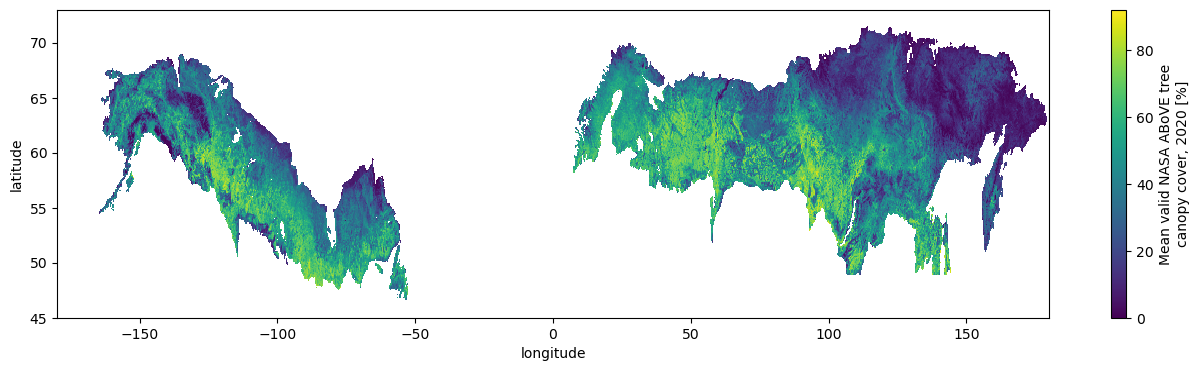

In [5]:
# Define your bounding box limits
min_lat, max_lat = 45, 73

# Create a boolean mask and drop values outside the box
mask = (
    (ds["latitude"] >= min_lat)
    & (ds["latitude"] <= max_lat)
)

from matplotlib import pyplot as plt
fig = plt.figure(figsize=(16,4))
ds.where(mask, drop=True).tree_canopy_cover_2020.plot()
plt.show()

# Site Selection Pipeline

### imports

In [4]:
# %pip install numpy pandas scipy xarray netCDF4 matplotlib

from pathlib import Path
import hashlib
import json
import os
import time
import uuid

import numpy as np
import pandas as pd
import xarray as xr

VERSION = "2.0.0"
EARTH_KM = 6371.0088
CORE = ["air_temperature_mean", "snowfall_mean", "relative_humidity_mean", "wind_speed_mean"]
LABELS = {
    "tree_canopy_cover_2020": "Mean canopy cover",
    "air_temperature_mean": "Air temperature", "snowfall_mean": "Estimated snowfall",
    "relative_humidity_mean": "Relative humidity", "wind_speed_mean": "Wind speed",
    "air_temperature_daily_sd": "Daily temperature SD",
    "snowfall_daily_sd": "Daily snowfall SD", "relative_humidity_daily_sd": "Daily RH SD",
    "wind_speed_daily_sd": "Daily wind SD", "above_freezing_day_fraction": "Days above freezing",
    "freeze_thaw_day_fraction": "Freeze–thaw days", "snowfall_day_fraction": "Snowfall days",
}


from IPython.display import display, Image, FileLink

print("Notebook working directory:", Path.cwd())


Notebook working directory: /home/s1803229/Chapter_2/notebooks


### settings

In [74]:
INPUT_NC = Path("../../scratch/climate_site_selection/era5_luke_winter_climatology_with_canopy.nc")
OUTPUT_DIR = Path("../../scratch/climate_site_selection/regional_site_selection")

WIDTH_KM = 400                         # Width along the central latitude of a box.
HEIGHT_KM = 400                        # North–south height.
CANDIDATE_SPACING_KM = 100             # Try 50 km for a finer search or 200 km boxes.
MIN_REGION_CANOPY_FRACTION = 0.50      # Region area in grid cells with valid canopy >10%.
MIN_CANOPY_COVER = 10.0                # Strict lower bound for eligible grid-cell canopy (%).
MIN_TEMPORAL_COVERAGE = 0.50           # every winter needs x% of days having valid measurement to be included
MIN_USABLE_FRACTION = 0.80             # Eligible area / entire box area.
MIN_CELL_SNOWFALL = None               # Optional minimum; same units as snowfall_mean.

SELECTION_VARIABLES = [
    "air_temperature_mean",
    "snowfall_mean",
    "relative_humidity_mean",
    "wind_speed_mean",
    "tree_canopy_cover_2020",
]
DIAGNOSTIC_VARIABLES = [
    "air_temperature_daily_sd", "snowfall_daily_sd",
    "relative_humidity_daily_sd", "wind_speed_daily_sd",
    "above_freezing_day_fraction", "freeze_thaw_day_fraction", "snowfall_day_fraction",
]
SAMPLE_SIZES = list(range(7, 21))       # Test every size from 6 to 25.
RANDOM_SEED = 1729
RESTARTS = 10                           # Independent annealing attempts per size.
ITERATIONS = 20000                     # Proposals per attempt.
MAX_OVERLAP_FRACTION = 0.0             # Selected footprints must not overlap.
FIGURE_DPI = 170

KL_BIN_COUNTS = [10, 15, 25]  # Fixed histogram resolutions for sensitivity checks.
REPORT_SAMPLE_SIZES = [6, 10, 15]      # Detailed report sections, in this order; None = all.
VERSION = "3.2"  # New caches for the revised method.

The next cell assembles these settings in memory. To change an experiment, edit and rerun the settings cell, then rerun the desired processing stage. That stage checks whether its preceding results can be reused.

In [75]:
def current_config():
    return {
        "input_nc": str(INPUT_NC),
        "output_dir": str(OUTPUT_DIR),
        "candidates": {
            "width_km": WIDTH_KM,
            "height_km": HEIGHT_KM,
            "spacing_km": CANDIDATE_SPACING_KM,
            "min_region_canopy_fraction": MIN_REGION_CANOPY_FRACTION,
            "min_canopy_cover": MIN_CANOPY_COVER,
            "min_temporal_coverage": MIN_TEMPORAL_COVERAGE,
            "min_usable_fraction": MIN_USABLE_FRACTION,
            "min_cell_snowfall": MIN_CELL_SNOWFALL,
            "selection_variables": SELECTION_VARIABLES,
            "diagnostic_variables": DIAGNOSTIC_VARIABLES,
        },
        "selection": {
            "sample_sizes": SAMPLE_SIZES,
            "kl_bin_counts": KL_BIN_COUNTS,
            "seed": RANDOM_SEED,
            "restarts": RESTARTS,
            "iterations": ITERATIONS,
            "max_overlap_fraction": MAX_OVERLAP_FRACTION,
        },
        "diagnostics": {
            "dpi": FIGURE_DPI,
            "sample_sizes": (
                None if REPORT_SAMPLE_SIZES is None else [
                    n.item() if isinstance(n, np.generic) else n
                    for n in REPORT_SAMPLE_SIZES
                ]
            ),
        },
    }


print("Input:", INPUT_NC.resolve())
print("Results:", OUTPUT_DIR.resolve())

Input: /scratch/s1803229/climate_site_selection/era5_luke_winter_climatology_with_canopy.nc
Results: /scratch/s1803229/climate_site_selection/regional_site_selection


## 3. Shared data and area functions

Cell means and spatial standard deviations use spherical cell-area weights, i.e. cell areas are calculated using Earth approximated as a sphere and weighted accordingly. A spatial SD describes variation **between cells in a region**; it is distinct from the input daily SD, which describes **variation through time**.

In [76]:
def log(message):
    # Show progress immediately, with the current time.
    print(time.strftime("[%H:%M:%S] ") + str(message), flush=True)


def digest(value):
    # Give a combination of settings a repeatable experiment ID.
    # Later code uses this ID in the results-folder name.
    text = json.dumps(value, sort_keys=True, allow_nan=False)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:16]


def atomic_json(path, value):
    # Save a small record: settings, completed variables, or finished experiments.
    # Later code reads these records to decide what can be reused or skipped.
    path = Path(path)
    temp = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")

    try:
        temp.write_text(
            json.dumps(value, indent=2, allow_nan=False),
            encoding="utf-8",
        )  # Write to a temporary file first.
        os.replace(temp, path)  # Replace the final file only when writing succeeds.
    finally:
        temp.unlink(missing_ok=True)  # Remove any leftover temporary file.


def atomic_csv(path, table):
    # Save actual tables, including candidate summaries and selected sites.
    # The temporary-file approach protects an existing table from a partial write.
    path = Path(path)
    temp = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")

    try:
        table.to_csv(temp, index=False)
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def source_signature(path):
    # Record which input NetCDF this experiment uses.
    # Include this information in the experiment ID so an updated NetCDF
    # does not accidentally reuse results calculated from an older file.
    p = Path(path).expanduser().resolve()
    s = p.stat()

    return {
        "path": str(p),           # Full input-file location.
        "bytes": s.st_size,       # File size.
        "mtime_ns": s.st_mtime_ns,  # Last modification time.
    }  # This checks file metadata, without reading the whole NetCDF.


def edges(centres):
    # Convert cell-centre coordinates into cell boundaries.
    # Example: centres [10, 11, 12] → edges [9.5, 10.5, 11.5, 12.5].
    # We need boundaries to calculate areas and align study boxes to whole cells.
    centres = np.asarray(centres, dtype=np.float64)

    if centres.ndim != 1 or centres.size < 2:
        raise ValueError("Expected a 1D coordinate array with at least two centres")

    d = np.diff(centres)  # Spacing between neighbouring cell centres.

    if (
        not np.all(np.isfinite(centres))
        or not np.all(d > 0)
        or not np.allclose(d, np.median(d), rtol=1e-4, atol=1e-6)
    ):
        raise ValueError(
            "Expected regular, increasing, unique latitude and longitude coordinates"
        )

    return np.r_[
        centres[0] - d[0] / 2,           # Outer boundary before the first centre.
        (centres[:-1] + centres[1:]) / 2,  # Boundaries between neighbouring centres.
        centres[-1] + d[-1] / 2,         # Outer boundary after the last centre.
    ]


def open_grid(path):
    # Open the NetCDF and arrange its grid consistently for later calculations.
    ds = xr.open_dataset(path)

    try:
        for name in ["latitude", "longitude"]:
            if ds[name].dims != (name,):
                raise ValueError(f"Expected 1D {name} coordinates")

        ds = ds.assign_coords(
            longitude=(ds.longitude + 180) % 360 - 180
        )  # Express longitude as −180 to 180 rather than 0 to 360.

        ds = ds.sortby("latitude").sortby("longitude")
        # Data now run south → north and west → east.

        edges(ds.latitude.values)
        edges(ds.longitude.values)
        # Check that both coordinates have regular spacing.

        return ds  # Return the open dataset for the caller to use and close.

    except Exception:
        ds.close()  # Close the file if preparation fails.
        raise


def map_values(ds, name):
    # Load one variable as a numerical map, with rows = latitude, columns = longitude.
    a = ds[name]

    if set(a.dims) != {"latitude", "longitude"}:
        raise ValueError(
            f"{name} has dimensions {a.dims}; "
            "use the collapsed 2D climatology NetCDF"
        )

    return (
        a.transpose("latitude", "longitude")
        .values.astype(np.float64)
    )  # Load this map into memory, using precision suited to the calculations.


def canopy_grid_mask(ds, cfg):
    # This mask tests grid-cell canopy values, not candidate-region coverage.
    cc = map_values(ds, "tree_canopy_cover_2020")
    coverage = map_values(ds, "tree_canopy_coverage_fraction")
    canopy_cells = (
        np.isfinite(cc) & (cc > cfg["min_canopy_cover"]) & (cc <= 100)
        & np.isfinite(coverage) & (coverage > 0) & (coverage <= 1.001)
    )
    # Positive source-data coverage is required, but there is no 75% cell test.
    return cc, canopy_cells


def read_domain(ds, cfg):
    # Usable grid cells have qualifying canopy AND adequate climate data.
    cc, canopy_cells = canopy_grid_mask(ds, cfg)
    valid = canopy_cells.copy()

    for name in CORE:
        a = map_values(ds, name)
        valid &= np.isfinite(a)  # Require valid temperature, snowfall, RH and wind.

        if name in ["snowfall_mean", "wind_speed_mean"]:
            valid &= a >= 0

        if name == "relative_humidity_mean":
            valid &= (a >= 0) & (a <= 100)

        if cfg["min_temporal_coverage"] is not None:
            coverage_name = name + "_min_period_valid_fraction"

            if coverage_name not in ds:
                raise ValueError(
                    f"Missing {coverage_name}; use the combined script's NetCDF "
                    "or set MIN_TEMPORAL_COVERAGE = None to disable this check"
                )

            frac = map_values(ds, coverage_name)
            valid &= (
                np.isfinite(frac)
                & (frac >= cfg["min_temporal_coverage"])
            )  # Enough valid daily records in every original winter–period.

    for name in cfg["selection_variables"]:
        if name not in CORE:
            valid &= np.isfinite(map_values(ds, name))
            # Require valid values for any additional selection variables.

    if cfg["min_cell_snowfall"] is not None:
        valid &= (
            map_values(ds, "snowfall_mean")
            >= cfg["min_cell_snowfall"]
        )  # Apply a snowfall minimum only if you specify one.

    if not valid.any():
        raise ValueError(
            "No eligible cells remain; inspect data coverage and thresholds"
        )

    return cc, valid  # Return canopy cover and the eligibility mask.


def rect_area(w, s, e, n):
    # Calculate a latitude/longitude rectangle's area in km².
    # Used for cell-area weights, study-box areas and box overlap.
    return (
        EARTH_KM**2
        * np.deg2rad(np.asarray(e) - np.asarray(w))
        * (
            np.sin(np.deg2rad(n))
            - np.sin(np.deg2rad(s))
        )
    )  # Account for longitude lines converging toward the poles.


def integral(a):
    # Prepare cumulative sums once, so thousands of boxes can be summarised quickly.
    out = np.zeros(
        (a.shape[0] + 1, a.shape[1] + 1),
        dtype=np.float64,
    )  # The extra zero row and column make edge calculations straightforward.

    out[1:, 1:] = np.cumsum(
        np.cumsum(a, axis=0),
        axis=1,
    )

    return out


def rect_sum(table, r0, r1, c0, c1):
    # Retrieve a box's sum from the cumulative table using only four entries.
    # Equivalent to summing the original array over [r0:r1, c0:c1].
    return (
        table[r1, c1]
        - table[r0, c1]
        - table[r1, c0]
        + table[r0, c0]
    )

## 4. Candidate footprint construction

Regions are approximately 400 × 400 km, spaced at 100 km and snapped outward to whole climate cells. At least 50% of each footprint must contain eligible cells. Candidate climate and canopy means use those eligible cells; candidates receive equal weight in the cLHS population.

In [77]:
def candidate_boxes(lat, lon, valid, cfg):
    le, oe = edges(lat), edges(lon)
    rows, cols = np.where(valid)

    step = cfg["spacing_km"]
    width, height = cfg["width_km"], cfg["height_km"]

    if min(step, width, height) <= 0:
        raise ValueError(
            "Footprint dimensions and candidate spacing must be positive"
        )

    dlat = np.rad2deg(step / EARTH_KM)
    half_h = np.rad2deg(height / (2 * EARTH_KM))

    lat_min, lat_max = lat[rows.min()], lat[rows.max()]
    lon_min, lon_max = lon[cols.min()], lon[cols.max()]

    records, seen = [], set()
    skipped = 0

    centres_lat = np.arange(
        np.ceil(lat_min / dlat) * dlat,
        lat_max + 1e-10,
        dlat,
    )  # Place centres on a repeatable grid with the requested spacing.

    for cy in centres_lat:
        cos_lat = np.cos(np.deg2rad(cy))
        dlon = np.rad2deg(step / (EARTH_KM * cos_lat))
        half_w = np.rad2deg(width / (2 * EARTH_KM * cos_lat))
        # Adjust longitude spacing and box width for latitude.

        centres_lon = np.arange(
            np.ceil(lon_min / dlon) * dlon,
            lon_max + 1e-10,
            dlon,
        )

        for cx in centres_lon:
            west, east = cx - half_w, cx + half_w
            south, north = cy - half_h, cy + half_h

            if (
                west < max(-180, oe[0])
                or east > min(180, oe[-1])
                or south < max(-90, le[0])
                or north > min(90, le[-1])
            ):
                skipped += 1
                continue  # Exclude incomplete boxes and dateline-crossing boxes.

            c0 = max(0, np.searchsorted(oe, west, side="right") - 1)
            c1 = min(len(lon), np.searchsorted(oe, east, side="left"))
            r0 = max(0, np.searchsorted(le, south, side="right") - 1)
            r1 = min(len(lat), np.searchsorted(le, north, side="left"))
            # Snap boundaries outward so every included cell is complete.

            box_indices = (r0, r1, c0, c1)

            if box_indices in seen or r0 == r1 or c0 == c1:
                continue

            seen.add(box_indices)

            w, e = oe[c0], oe[c1]
            s, n = le[r0], le[r1]
            center_lat, center_lon = (s + n) / 2, (w + e) / 2

            records.append({
                "candidate_id": f"C{len(records) + 1:06d}",
                "longitude": center_lon,
                "latitude": center_lat,
                "west": w,
                "south": s,
                "east": e,
                "north": n,
                "row0": r0,
                "row1": r1,
                "col0": c0,
                "col1": c1,
                "area_km2": float(rect_area(w, s, e, n)),
                "width_at_centre_km": (
                    EARTH_KM
                    * np.deg2rad(e - w)
                    * np.cos(np.deg2rad(center_lat))
                ),
                "height_km": EARTH_KM * np.deg2rad(n - s),
            })

    if not records:
        raise ValueError(
            "No complete candidate boxes fit this grid; "
            "reduce width/height or spacing"
        )

    log(
        f"Generated {len(records):,} unique grid-aligned boxes; "
        f"skipped {skipped:,} at domain/dateline boundaries"
    )

    return pd.DataFrame(records)


def geojson(table, path):
    # Save geographic box boundaries for plotting or opening in GIS software.
    features = []

    for _, row in table.iterrows():
        w, s, e, n = [
            float(row[k]) for k in ["west", "south", "east", "north"]
        ]

        props = {
            k: (
                None if pd.isna(v)
                else v.item() if isinstance(v, np.generic)
                else v
            )
            for k, v in row.items()
        }

        features.append({
            "type": "Feature",
            "properties": props,
            "geometry": {
                "type": "Polygon",
                "coordinates": [
                    [[w, s], [e, s], [e, n], [w, n], [w, s]]
                ],
            },
        })

    atomic_json(
        path,
        {"type": "FeatureCollection", "features": features},
    )


def build_candidates(config):
    cfg = config["candidates"]

    signature = {
        "version": VERSION,
        "summary_method": "region_canopy_screen_v3",
        "source": source_signature(config["input_nc"]),
        "candidates": cfg,
    }

    folder = Path(config["output_dir"]) / (
        "candidates_" + digest(signature)
    )
    folder.mkdir(parents=True, exist_ok=True)

    manifest = folder / "manifest.json"

    if manifest.exists():
        log(f"Reusing completed candidate catalogue: {folder}")
        return folder

    checkpoint = folder / "candidate_progress.csv"
    done_path = folder / "progress.json"

    with open_grid(config["input_nc"]) as ds:
        lat, lon = ds.latitude.values, ds.longitude.values
        cc, valid = read_domain(ds, cfg)
        _, canopy_cells = canopy_grid_mask(ds, cfg)
        if not 0 <= cfg["min_region_canopy_fraction"] <= 1:
            raise ValueError("min_region_canopy_fraction must lie between 0 and 1")
        le, oe = edges(lat), edges(lon)

        row_area = (
            EARTH_KM**2
            * np.deg2rad(oe[1] - oe[0])
            * np.diff(np.sin(np.deg2rad(le)))
        )
        weights = np.broadcast_to(
            row_area[:, None],
            (len(lat), len(lon)),
        )  # Physical area of each grid cell, in km².

        if checkpoint.exists() and done_path.exists():
            progress = json.loads(done_path.read_text())
            table = pd.read_csv(checkpoint)
            completed = progress["completed_variables"]

            log(
                f"Resuming candidate summaries after "
                f"{len(completed)} variables"
            )

        else:
            table = candidate_boxes(lat, lon, valid, cfg)

            idx = [
                table[k].to_numpy(dtype=int)
                for k in ["row0", "row1", "col0", "col1"]
            ]

            table["canopy_area_km2"] = rect_sum(
                integral(weights * canopy_cells), *idx
            )
            table["canopy_fraction"] = table.canopy_area_km2 / table.area_km2
            table["canopy_pass"] = (
                table.canopy_fraction >= cfg["min_region_canopy_fraction"] - 1e-12
            )
            # Denominator is the entire candidate region, including missing data.
            # Count each qualifying climate-grid cell by its full physical area.

            table["usable_area_km2"] = rect_sum(
                integral(weights * valid), *idx
            )
            table["usable_fraction"] = (
                table.usable_area_km2 / table.area_km2
            )

            table["coverage_pass"] = (
                table.canopy_pass
                & (table.usable_area_km2 > 0)
                & (
                    table.usable_fraction
                    >= cfg["min_usable_fraction"]
                )
            )  # No separate minimum-cell-count requirement.

            atomic_csv(folder / "footprint_screening.csv", table)

            table = table.loc[
                table.coverage_pass
            ].reset_index(drop=True)

            if table.empty:
                raise ValueError(
                    "No candidate regions pass the canopy and usable-area tests. Inspect "
                    f"{folder / 'footprint_screening.csv'}"
                )

            completed = []
            atomic_csv(checkpoint, table)
            atomic_json(
                done_path,
                {"completed_variables": completed},
            )

        idx = [
            table[k].to_numpy(dtype=int)
            for k in ["row0", "row1", "col0", "col1"]
        ]

        required = list(dict.fromkeys(
            cfg["selection_variables"]
            + ["tree_canopy_cover_2020"]
        ))  # Continuous canopy is included in selection.

        missing_required = [
            name for name in required if name not in ds
        ]

        if missing_required:
            raise ValueError(
                "Required variables absent from NetCDF: "
                + ", ".join(missing_required)
            )

        requested = list(dict.fromkeys(
            required + cfg["diagnostic_variables"]
        ))
        names = [name for name in requested if name in ds]
        missing = [name for name in requested if name not in ds]
        units = {
            name: ds[name].attrs.get("units", "")
            for name in names
        }

        if missing:
            log(
                "Optional diagnostic variables absent: "
                + ", ".join(missing)
            )

        for name in names:
            if name in completed:
                continue  # Reuse variables already saved in the checkpoint.

            a = map_values(ds, name)
            support = valid & np.isfinite(a)
            wa = weights * support

            denominator = rect_sum(integral(wa), *idx)

            offset = float(np.median(a[support])) if support.any() else 0.0
            centered = np.where(support, a - offset, 0.0)
            # Subtract a reference value to improve numerical precision.

            mean = np.divide(
                rect_sum(integral(wa * centered), *idx),
                denominator,
                out=np.full(len(table), np.nan),
                where=denominator > 0,
            )

            second = np.divide(
                rect_sum(integral(wa * centered**2), *idx),
                denominator,
                out=np.full(len(table), np.nan),
                where=denominator > 0,
            )

            table[name] = mean + offset
            table[name + "__spatial_sd"] = np.sqrt(
                np.maximum(second - mean**2, 0)
            )
            table[name + "__valid_fraction"] = (
                denominator / table.usable_area_km2
            )

            completed.append(name)
            atomic_csv(checkpoint, table)
            atomic_json(
                done_path,
                {"completed_variables": completed},
            )

            log(f"Summarised {name} for {len(table):,} regions")

        atomic_csv(folder / "candidates.csv", table)

        # Save smaller climate maps for the later coloured climate-region map.
        stride = max(
            1, int(np.ceil(max(len(lat), len(lon)) / 900))
        )
        small_valid = valid[::stride, ::stride]
        map_variables = cfg["selection_variables"]

        climate_maps = np.stack([
            np.where(
                small_valid,
                map_values(ds, name)[::stride, ::stride],
                np.nan,
            ).astype("float32")
            for name in map_variables
        ])  # Dimensions: variable, latitude, longitude.

        map_path = folder / "map_background.npz"
        temporary = folder / (
            "map_background." + uuid.uuid4().hex + ".tmp.npz"
        )

        try:
            np.savez_compressed(
                temporary,
                latitude=lat[::stride],
                longitude=lon[::stride],
                eligible=small_valid,
                climate_variables=np.asarray(map_variables, dtype=str),
                climate_maps=climate_maps,
            )
            os.replace(temporary, map_path)
        finally:
            temporary.unlink(missing_ok=True)

        geojson(table, folder / "candidates.geojson")

        atomic_json(manifest, {
            **signature,
            "candidate_count": len(table),
            "units": units,
            "absent_diagnostics": missing,
            "selection_variables": cfg["selection_variables"],
            "area_definition": (
                "Spherical latitude/longitude rectangles snapped outward "
                "to grid edges; width is at centre latitude"
            ),
            "climate_population": (
                "Approximately equal-distance lattice of eligible candidate "
                "footprints; not individual cells or area-weighted land population"
            ),
        })  # Mark the candidate stage complete only after all outputs are saved.

    log(f"Saved candidate catalogue: {folder}")
    return folder

### Run the candidate stage

This stage checkpoints after each variable. If interrupted, rerunning it recreates the eligibility mask and continues the unfinished summaries. Changing footprint or eligibility settings creates a separate results directory. The original daily climate files and canopy TIFFs are not needed.

In [78]:
config = current_config()
candidate_dir = build_candidates(config)
candidates = pd.read_csv(candidate_dir / "candidates.csv")
print(f"{len(candidates):,} eligible candidate regions")
print("Saved in:", candidate_dir.resolve())
display(candidates.head())


[17:05:05] Generated 5,441 unique grid-aligned boxes; skipped 42 at domain/dateline boundaries
[17:05:06] Summarised air_temperature_mean for 1,040 regions
[17:05:06] Summarised snowfall_mean for 1,040 regions
[17:05:07] Summarised relative_humidity_mean for 1,040 regions
[17:05:07] Summarised wind_speed_mean for 1,040 regions
[17:05:08] Summarised tree_canopy_cover_2020 for 1,040 regions
[17:05:08] Summarised air_temperature_daily_sd for 1,040 regions
[17:05:08] Summarised snowfall_daily_sd for 1,040 regions
[17:05:09] Summarised relative_humidity_daily_sd for 1,040 regions
[17:05:10] Summarised wind_speed_daily_sd for 1,040 regions
[17:05:10] Summarised above_freezing_day_fraction for 1,040 regions
[17:05:10] Summarised freeze_thaw_day_fraction for 1,040 regions
[17:05:11] Summarised snowfall_day_fraction for 1,040 regions
[17:05:11] Saved candidate catalogue: ../../scratch/climate_site_selection/regional_site_selection/candidates_5d7de32479ad6485
1,040 eligible candidate regions
Sav

,candidate_id,longitude,latitude,west,south,east,north,row0,row1,col0,...,wind_speed_daily_sd__valid_fraction,above_freezing_day_fraction,above_freezing_day_fraction__spatial_sd,above_freezing_day_fraction__valid_fraction,freeze_thaw_day_fraction,freeze_thaw_day_fraction__spatial_sd,freeze_thaw_day_fraction__valid_fraction,snowfall_day_fraction,snowfall_day_fraction__spatial_sd,snowfall_day_fraction__valid_fraction
0,C000826,-85.80,49.45,-88.6,47.6,-83.0,51.3,1376,1413,914,...,1.0,0.350952,0.043936,1.0,0.189590,0.023476,1.0,0.621901,0.034919,1.0
1,C000827,-84.40,49.45,-87.2,47.6,-81.6,51.3,1376,1413,928,...,1.0,0.354619,0.037034,1.0,0.199630,0.018361,1.0,0.613733,0.026693,1.0
2,C000828,-83.00,49.45,-85.8,47.6,-80.2,51.3,1376,1413,942,...,1.0,0.354217,0.030961,1.0,0.201678,0.017031,1.0,0.620728,0.029281,1.0
3,C000829,-81.65,49.45,-84.5,47.6,-78.8,51.3,1376,1413,955,...,1.0,0.347905,0.028796,1.0,0.196276,0.019557,1.0,0.635592,0.032131,1.0
4,C000830,-80.25,49.45,-83.1,47.6,-77.4,51.3,1376,1413,969,...,1.0,0.341127,0.033151,1.0,0.188835,0.021624,1.0,0.651042,0.029966,1.0


### Select regions by marginal cLHS

For $p$ active variables and $n$ sites, let $c_{jb}$ be the number of selected sites in stratum $b$ of variable $j$. The only objective is

$$M = \frac{1}{pn}\sum_{j=1}^{p}\sum_{b=1}^{n}|c_{jb}-1|.$$

All five variables have equal weight. $M=0$ means exactly one selected region in every stratum of every variable. Quantile cut points use NumPy's linear interpolation; a value exactly on an internal cut belongs to the higher interval ```(searchsorted(..., side="right"))```. Constant variables are reported and excluded because they offer no stratification.

Simulated annealing changes one region at a time and rejects overlapping footprints. Retain the lowest objective across independent restarts. Sample sizes have different stratum boundaries and are shown for comparison; there is no automatic sample-size recommendation or coverage target. Choose ```SHOW_N``` from the tested sizes.

In [79]:
def overlap_against(box, others):
    # Intersection fraction relative to the smaller footprint; vectorized.
    others=np.asarray(others)
    if others.size==0:
        return np.empty(0)
    w=np.maximum(box[0],others[:,0]); s=np.maximum(box[1],others[:,1])
    e=np.minimum(box[2],others[:,2]); n=np.minimum(box[3],others[:,3])
    inter=rect_area(w,s,np.maximum(w,e),np.maximum(s,n))
    smaller=np.minimum(rect_area(*box),rect_area(others[:,0],others[:,1],others[:,2],others[:,3]))
    return inter/smaller




In [80]:
def make_kl_reference(table, variables, bin_counts):
    reference = {}
    for name in variables:
        population = table[name].to_numpy(float)
        if np.std(population) <= 1e-12:
            continue
        for nbins in bin_counts:
            boundaries = np.linspace(population.min(), population.max(), nbins + 1)
            counts = np.histogram(population, bins=boundaries)[0]
            reference[(nbins, name)] = (boundaries, counts / counts.sum())
    return reference


def calculate_kl(sample, reference):
    result = []
    for (nbins, name), (boundaries, population) in reference.items():
        counts = np.histogram(sample[name], bins=boundaries)[0]
        observed = counts / counts.sum()
        positive = observed > 0
        # Sample is a subset of the population: positive sample bins cannot have zero population.
        divergence = np.sum(observed[positive] * np.log(observed[positive] / population[positive]))
        result.append((nbins, name, float(max(0, divergence))))
    return result


def kl_elbow(x, y):
    # Exploratory continuous two-line fit, compared with a single straight line.
    # This is an explicit elbow heuristic, not Malone et al.'s 95% rule.
    order = np.argsort(x); x = np.asarray(x, float)[order]; y = np.asarray(y, float)[order]
    if len(x) < 7:
        return {"n": None, "reason": "Too few sizes for a two-slope comparison"}
    def fit(matrix):
        coef = np.linalg.lstsq(matrix, y, rcond=None)[0]
        residual = y - matrix @ coef
        return coef, max(float(residual @ residual), 1e-15)
    _, single_error = fit(np.column_stack([np.ones(len(x)), x]))
    single_bic = len(x) * np.log(single_error / len(x)) + 2 * np.log(len(x))
    options = []
    for knee in x[2:-2]:
        matrix = np.column_stack([np.ones(len(x)), x, np.maximum(x-knee, 0)])
        coef, error = fit(matrix)
        before, after = coef[1], coef[1] + coef[2]
        if before < after <= 0:
            bic = len(x)*np.log(error/len(x)) + 4*np.log(len(x))
            options.append((bic, knee, before, after))
    if not options:
        return {"n": None, "reason": "No declining curve with a flatter second slope"}
    bic, knee, before, after = min(options)
    if single_bic-bic < 6:
        return {"n": None, "reason": "No clear elbow compared with a straight line"}
    return {"n": int(knee), "bic_improvement": float(single_bic-bic),
            "slope_before": float(before), "slope_after": float(after)}


class Design:
    def __init__(self, table, variables, cfg, n):
        self.table, self.cfg, self.n = table, cfg, int(n)
        raw = table[variables].to_numpy(float)
        if not np.isfinite(raw).all():
            raise ValueError("Nonfinite candidate means")
        active = np.std(raw, axis=0) > 1e-12
        self.variables = list(np.array(variables)[active])
        self.dropped = list(np.array(variables)[~active])
        raw = raw[:, active]
        if not raw.shape[1]:
            raise ValueError("All selection variables are constant")
        self.raw = raw
        self.upper = np.triu_indices(raw.shape[1], 1)
        self.population_corr = self.correlation(raw)
        self.cuts = np.quantile(raw, np.arange(1, n) / n, axis=0)
        self.bins = np.column_stack([
            np.searchsorted(self.cuts[:, j], raw[:, j], side="right")
            for j in range(raw.shape[1])
        ])
        self.boxes = table[["west", "south", "east", "north"]].to_numpy(float)

    def counts(self, ids):
        return np.array([np.bincount(self.bins[ids, j], minlength=self.n)
                         for j in range(len(self.variables))])

    @staticmethod
    def correlation(x):
        centred = x - x.mean(axis=0)
        norms = np.sqrt((centred * centred).sum(axis=0))
        z = np.divide(centred, norms, out=np.zeros_like(centred), where=norms > 1e-12)
        return z.T @ z  # Constant sample columns have zero off-diagonal correlation.

    def components(self, ids):
        marginal = float(np.abs(self.counts(ids) - 1).sum())
        correlation = float(np.abs(
            self.correlation(self.raw[ids])[self.upper]
            - self.population_corr[self.upper]).sum())
        return {"M": marginal, "C": correlation, "objective": marginal + correlation}

    def objective(self, ids):
        return self.components(ids)["objective"]

    def compatible(self, new, others):
        return not len(others) or bool(np.all(
            overlap_against(self.boxes[new], self.boxes[others])
            <= self.cfg["max_overlap_fraction"] + 1e-12))

    def initial(self, rng):
        for attempt in range(100):
            ids = []
            for i in rng.permutation(len(self.table)):
                if self.compatible(i, ids):
                    ids.append(i)
                    if len(ids) == self.n:
                        return np.array(ids, dtype=int)
        raise ValueError(f"Could not initialise {self.n} non-overlapping regions")

    def anneal(self, seed):
        rng = np.random.default_rng(seed)
        ids = self.initial(rng)
        score = self.objective(ids)
        best, best_score = ids.copy(), score
        trace = []
        iterations = self.cfg["iterations"]
        deltas = []
        for _ in range(200):
            slot = int(rng.integers(self.n)); new = int(rng.integers(len(self.table)))
            if new not in ids and self.compatible(new, np.delete(ids, slot)):
                proposal = ids.copy(); proposal[slot] = new
                delta = abs(self.objective(proposal) - score)
                if delta > 1e-12:
                    deltas.append(delta)
        start_temperature = (float(np.median(deltas)) if deltas else 1.0) / -np.log(0.8)
        for i in range(iterations):
            if best_score == 0:
                break  # The known global lower bound has been reached.
            slot = int(rng.integers(self.n))
            new = int(rng.integers(len(self.table)))
            others = np.delete(ids, slot)
            if new in ids or not self.compatible(new, others):
                continue
            proposal = ids.copy()
            proposal[slot] = new
            proposed = self.objective(proposal)
            temperature = start_temperature * 0.001 ** (i / max(1, iterations - 1))
            if proposed <= score or rng.random() < np.exp((score - proposed) / temperature):
                ids, score = proposal, proposed
            if score < best_score:
                best, best_score = ids.copy(), score
            if i % max(1, iterations // 200) == 0:
                trace.append(dict(iteration=i, current_objective=score, best_objective=best_score))
        trace.append(dict(iteration=i + 1, current_objective=score, best_objective=best_score))
        return best, best_score, pd.DataFrame(trace)


def select_sites(config, candidate_dir=None):
    folder = Path(candidate_dir) if candidate_dir else build_candidates(config)
    table = pd.read_csv(folder / "candidates.csv")
    cfg = config["selection"]
    sizes = sorted(set(map(int, cfg["sample_sizes"])))
    if not sizes or min(sizes) < 1 or max(sizes) > len(table):
        raise ValueError("Invalid sample sizes for this catalogue")
    if cfg["iterations"] < 1 or cfg["restarts"] < 1:
        raise ValueError("Iterations and restarts must be positive")
    signature = {"version": VERSION, "candidate_dir": str(folder.resolve()), "selection": cfg}
    out = folder / ("selection_" + digest(signature))
    out.mkdir(exist_ok=True)
    if (out / "complete.json").exists():
        return out
    comparison, summary, kl_records = [], [], []
    kl_reference = make_kl_reference(table, config["candidates"]["selection_variables"], cfg["kl_bin_counts"])
    for n in sizes:
        design = Design(table, config["candidates"]["selection_variables"], cfg, n)
        dest = out / f"n{n:02d}"
        dest.mkdir(exist_ok=True)
        trials = []
        for restart in range(cfg["restarts"]):
            seed = cfg["seed"] + n * 10000 + restart
            checkpoint = dest / f"restart_{restart:02d}.json"
            if checkpoint.exists():
                saved = json.loads(checkpoint.read_text())
                ids = np.array(saved["ids"], dtype=int)
                score = design.objective(ids)
            else:
                ids, score, trace = design.anneal(seed)
                atomic_csv(dest / f"restart_{restart:02d}_trace.csv", trace)
                atomic_json(checkpoint, {"ids": ids.tolist(), "M": score, "seed": seed})
            trials.append((score, restart, ids))
            comparison.append(dict(n_sites=n, restart=restart, **design.components(ids)))
            for nbins, variable, value in calculate_kl(table.iloc[ids], kl_reference):
                kl_records.append(dict(n_sites=n, restart=restart, bins=nbins,
                                       variable=variable, KL=value))
        score, restart, ids = min(trials, key=lambda trial: (trial[0], trial[1]))
        chosen = table.iloc[ids].copy().reset_index(drop=True)
        chosen.insert(0, "site_id", [f"S{i+1:02d}" for i in range(n)])
        for j, name in enumerate(design.variables):
            chosen[name + "__stratum"] = design.bins[ids, j] + 1
        atomic_csv(dest / "selected_sites.csv", chosen)
        geojson(chosen, dest / "selected_sites.geojson")
        records = []
        for j, name in enumerate(design.variables):
            population_counts = np.bincount(design.bins[:, j], minlength=n)
            boundaries = np.r_[table[name].min(), design.cuts[:, j], table[name].max()]
            for b, count in enumerate(design.counts(ids)[j]):
                records.append(dict(variable=name, stratum=b+1,
                    quantile_lower=b/n, quantile_upper=(b+1)/n,
                    lower=boundaries[b], upper=boundaries[b+1],
                    upper_inclusive=b == n-1,
                    population_count=int(population_counts[b]), selected_count=int(count),
                    occupied=bool(count)))
        atomic_csv(dest / "stratum_occupancy.csv", pd.DataFrame(records))
        atomic_json(dest / "design.json", {**design.components(ids), "n_sites": n,
                    "active_variables": design.variables, "constant_variables": design.dropped})
        summary.append(dict(n_sites=n, **design.components(ids), best_restart=restart,
            occupied_strata=int((design.counts(ids) > 0).sum()),
            requested_strata=n*len(design.variables)))
        log(f"Selected {n} sites: objective={score:.4f}; constant variables: {design.dropped}")
    atomic_csv(out / "sample_size_comparison.csv", pd.DataFrame(comparison))
    atomic_csv(out / "sample_size_summary.csv", pd.DataFrame(summary))
    kl = pd.DataFrame(kl_records)
    atomic_csv(out / "kl_by_variable.csv", kl)
    aggregate = kl.groupby(["n_sites", "restart", "bins"], as_index=False).KL.mean()
    atomic_csv(out / "kl_repeats.csv", aggregate)
    curve = aggregate.groupby(["n_sites", "bins"], as_index=False).agg(
        mean_KL=("KL", "mean"), sd_KL=("KL", "std"))
    atomic_csv(out / "kl_summary.csv", curve)
    knees = {}
    for nbins, group in curve.groupby("bins"):
        knees[str(nbins)] = kl_elbow(group.n_sites.to_numpy(), group.mean_KL.to_numpy())
    atomic_json(out / "elbow_diagnostics.json", knees)
    atomic_json(out / "complete.json", signature)
    return out


In [81]:
config = current_config()
candidate_dir = build_candidates(config)
selection_dir = select_sites(config, candidate_dir)
display(pd.read_csv(selection_dir / "sample_size_summary.csv"))

[17:05:13] Reusing completed candidate catalogue: ../../scratch/climate_site_selection/regional_site_selection/candidates_5d7de32479ad6485
[17:05:25] Selected 7 sites: objective=0.9483; constant variables: []
[17:05:37] Selected 8 sites: objective=1.5603; constant variables: []
[17:05:48] Selected 9 sites: objective=2.6282; constant variables: []
[17:05:59] Selected 10 sites: objective=1.0193; constant variables: []
[17:06:09] Selected 11 sites: objective=4.3190; constant variables: []
[17:06:19] Selected 12 sites: objective=4.8707; constant variables: []
[17:06:29] Selected 13 sites: objective=6.4820; constant variables: []
[17:06:39] Selected 14 sites: objective=4.9176; constant variables: []
[17:06:49] Selected 15 sites: objective=6.8206; constant variables: []
[17:06:58] Selected 16 sites: objective=8.7136; constant variables: []
[17:07:07] Selected 17 sites: objective=8.7977; constant variables: []
[17:07:16] Selected 18 sites: objective=12.4115; constant variables: []
[17:07:25] 

,n_sites,M,C,objective,best_restart,occupied_strata,requested_strata
0,7,0.0,0.948331,0.948331,0,35,35
1,8,0.0,1.560307,1.560307,5,40,40
2,9,2.0,0.628236,2.628236,8,44,45
3,10,0.0,1.019310,1.019310,6,50,50
4,11,4.0,0.319000,4.319000,0,53,55
5,12,4.0,0.870716,4.870716,1,58,60
6,13,6.0,0.481983,6.481983,4,62,65
7,14,4.0,0.917560,4.917560,6,68,70
8,15,6.0,0.820605,6.820605,6,72,75
9,16,8.0,0.713637,8.713637,8,76,80


### Quantile maps and diagnostics

Each variable has two map panels: all strata delineates the \(n\) intervals using discrete colours; occupied strata retains those colours only for intervals containing at least one selected region and shows the others in grey. Adjacent tiles in different strata have outlined boundaries. Small tiles indicate candidate locations on the sampling lattice, not individual climate pixels or full footprints. Black outlines show selected footprints; numbered markers identify sites.

The interval key gives actual variable cut points and selected counts. Colours identify strata, not selected sites. A stratum can occur in several disconnected geographic areas. Occupancy is assessed separately for each variable: different sites can occupy corresponding intervals in different panels. This does not define a joint representation class.

Histograms use those same cut points. Occupancy counts show the target of one per interval directly. Spatial SDs remain descriptive only. No coverage threshold or coverage-target line is drawn.

In [88]:
def plot_kl_exploration(selection_dir):
    """Read existing selection results and return the KL figure; no report needed."""
    import matplotlib.pyplot as plt
    selection = Path(selection_dir)
    curve = pd.read_csv(selection / "kl_summary.csv")
    knees = json.loads((selection / "elbow_diagnostics.json").read_text())
    bin_counts = sorted(curve.bins.unique())
    fig, axes = plt.subplots(1, len(bin_counts), figsize=(6*len(bin_counts), 5), squeeze=False, layout="constrained")
    for ax, nbins in zip(axes.flat, bin_counts):
        group = curve[curve.bins == nbins].sort_values("n_sites")
        ax.errorbar(group.n_sites, group.mean_KL, yerr=group.sd_KL,
                    fmt="o-", capsize=3, color="#426d82", label="Mean ± SD across repeats")
        knee = knees[str(nbins)].get("n")
        if knee is not None:
            ax.axvline(knee, color="#b34b35", ls="--", label=f"Exploratory elbow: {knee}")
        ax.set(xlabel="Number of selected regions", ylabel="Mean KL(sample || candidates)",
               title=f"{nbins} fixed histogram bins per variable")
        ax.grid(alpha=0.2); ax.legend(fontsize=8)
    return fig


def report_sample_sizes(requested, available):
    available = [int(n) for n in available]
    if requested is None:
        return available
    if isinstance(requested, (str, bytes)):
        raise ValueError("Report sample sizes must be a list of integers or None")
    result = []
    for n in requested:
        if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
            raise ValueError("Report sample sizes must be integers")
        n = int(n)
        if n not in available:
            raise ValueError(f"No completed selection for n={n}; available: {available}")
        if n not in result:
            result.append(n)
    return result


def diagnose(config, candidate_dir=None, selection_dir=None):
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap, BoundaryNorm
    from matplotlib.patches import Rectangle
    from html import escape
    try:
        import cartopy.crs as ccrs
        import cartopy.feature as cfeature
    except ImportError:
        ccrs = None  # Plain longitude/latitude plots work without cartopy.

    folder = Path(candidate_dir) if candidate_dir else build_candidates(config)
    selection = Path(selection_dir) if selection_dir else select_sites(config, folder)
    table = pd.read_csv(folder / "candidates.csv")
    manifest = json.loads((folder / "manifest.json").read_text())
    units = manifest["units"]
    output = selection / ("diagnostics_" + digest({"version": VERSION, "report_layout": "all-usable-grid-v1", **config["diagnostics"]}))
    output.mkdir(exist_ok=True)
    summary = pd.read_csv(selection / "sample_size_summary.csv")
    trials = pd.read_csv(selection / "sample_size_comparison.csv")
    report_sizes = report_sample_sizes(
        config["diagnostics"].get("sample_sizes"), summary.n_sites
    )
    pages = []

    def values(frame, name):
        a = frame[name].to_numpy(float)
        return a - 273.15 if name == "air_temperature_mean" and units.get(name, "").lower() in ("k", "kelvin") else a

    def label(name):
        unit = units.get(name, "")
        if name == "air_temperature_mean" and unit.lower() in ("k", "kelvin"):
            unit = "°C"
        return LABELS.get(name, name) + (f" ({unit})" if unit else "")

    def save(fig, name):
        fig.savefig(output / name, dpi=config["diagnostics"]["dpi"], bbox_inches="tight")
        plt.close(fig)
        return name

    # Screening contains both retained and rejected complete candidate regions.
    screening = pd.read_csv(folder / "footprint_screening.csv")
    viable = screening.candidate_id.isin(table.candidate_id)
    with open_grid(config["input_nc"]) as grid:
        _, map_usable = read_domain(grid, config["candidates"])
        map_lat_edges = edges(grid.latitude.values)
        map_lon_edges = edges(grid.longitude.values)
    rr, cc = np.where(map_usable)
    # Crop empty outer margins only; do not subsample or remove any usable cell.
    r0, r1 = int(rr.min()), int(rr.max()) + 1
    c0, c1 = int(cc.min()), int(cc.max()) + 1
    map_mask = map_usable[r0:r1, c0:c1]
    map_y = map_lat_edges[r0:r1+1]
    map_x = map_lon_edges[c0:c1+1]
    extent = [max(-180, min(map_x[0], screening.west.min()) - 0.2),
              min(180, max(map_x[-1], screening.east.max()) + 0.2),
              max(-90, min(map_y[0], screening.south.min()) - 0.2),
              min(90, max(map_y[-1], screening.north.max()) + 0.2)]

    for n in report_sizes:
        selected = pd.read_csv(selection / f"n{n:02d}" / "selected_sites.csv")
        ids = table.index[table.candidate_id.isin(selected.candidate_id)].to_numpy()
        design = Design(table, config["candidates"]["selection_variables"], config["selection"], n)
        counts = design.counts(ids)
        p = len(design.variables)
        colours = plt.get_cmap("turbo")(np.linspace(0.06, 0.94, n))
        image_names = []
        occupancy = pd.read_csv(selection / f"n{n:02d}" / "stratum_occupancy.csv")
        mapping = table[["candidate_id", "latitude", "longitude"]].copy()
        for j, name in enumerate(design.variables):
            bins = design.bins[:, j]
            mapping[name + "__stratum"] = bins + 1
            mapping[name + "__stratum_occupied"] = counts[j, bins] > 0
            fig = plt.figure(figsize=(20, 5.5 + 0.38*np.ceil(n/8)), layout="constrained")
            gs = fig.add_gridspec(2, 1, height_ratios=[3, 0.7 + 0.35*np.ceil(n/8)])
            projection = {"projection": ccrs.PlateCarree()} if ccrs else {}
            ax = fig.add_subplot(gs[0, 0], **projection)
            kwargs = {"transform": ccrs.PlateCarree()} if ccrs else {}
            with open_grid(config["input_nc"]) as grid:
                field = map_values(grid, name)[r0:r1, c0:c1]
            # Candidate quantile cuts in stored units; grid cells use their own values.
            cell_bins = np.searchsorted(design.cuts[:, j], field, side="right")
            cell_bins = np.ma.array(cell_bins, mask=~map_mask | ~np.isfinite(field))
            cmap = ListedColormap(colours)
            cmap.set_bad((1, 1, 1, 0))
            ax.pcolormesh(map_x, map_y, cell_bins, cmap=cmap,
                          norm=BoundaryNorm(np.arange(n+1)-0.5, n),
                          shading="flat", rasterized=True, zorder=1, **kwargs)
            # for status, opacity, text in [
            #     (False, 0.20, "Rejected candidate centre"),
            #     (True, 0.85, "Viable candidate centre"),
            # ]:
            #     subset = screening.loc[viable == status]
            #     ax.scatter(subset.longitude, subset.latitude, s=12, marker="o",
            #                facecolors="none", edgecolors="black", linewidths=0.7,
            #                alpha=opacity, label=text, zorder=3, **kwargs)
            if ccrs:
                ax.set_extent(extent, crs=ccrs.PlateCarree())
                ax.coastlines(resolution="110m", linewidth=0.45)
                ax.gridlines(draw_labels={"bottom": "x", "left": "y"}, linewidth=0.3, alpha=0.35)
            else:
                ax.set(xlim=extent[:2], ylim=extent[2:], xlabel="Longitude", ylabel="Latitude")
            for i, (_, row) in enumerate(selected.iterrows()):
                ax.add_patch(Rectangle((row.west, row.south), row.east-row.west,
                    row.north-row.south, fill=False, ec="black", lw=1.2,
                    label="Selected region" if i == 0 else None, zorder=4, **kwargs))
                ax.plot(row.longitude, row.latitude, "wo", ms=4, mec="black", zorder=5, **kwargs)
                ax.text(row.longitude, row.latitude, str(row.site_id), fontsize=7,
                        zorder=6, **kwargs)
            ax.legend(loc="upper right", fontsize=9, framealpha=0.95)
            ax.set_title("All usable grid cells; selected candidates and regions shown")
            key = fig.add_subplot(gs[1, 0])
            columns = min(n, 8); key_rows = int(np.ceil(n / columns))
            key.set(xlim=(0, columns), ylim=(0, key_rows))
            for b in range(n):
                col, row = b % columns, key_rows - 1 - b // columns
                key.add_patch(Rectangle((col, row+0.68), 0.95, 0.25, color=colours[b]))
                part = occupancy[(occupancy.variable == name) & (occupancy.stratum == b+1)].iloc[0]
                lo, hi = part.lower, part.upper
                if name == "air_temperature_mean" and units.get(name, "").lower() in ("k", "kelvin"):
                    lo, hi = lo-273.15, hi-273.15
                # Cell values can extend beyond the range of candidate means.
                interval = (f"< {hi:.3g}" if b == 0 else
                            f"≥ {lo:.3g}" if b == n-1 else
                            f"[{lo:.3g}, {hi:.3g})")
                key.text(col+0.47, row+0.46, f"Q{b+1}: {interval}", ha="center", fontsize=9)
                key.text(col+0.47, row+0.15, f"Selected sites: {counts[j,b]}", ha="center", fontsize=9,
                         fontweight="bold" if counts[j,b] == 0 else "normal")
            key.axis("off")
            fig.suptitle(f"{n} sites • {label(name)} • grid-cell values using candidate quantile cuts", fontsize=14)
            image_names.append(save(fig, f"n{n:02d}_quantiles_{name}.png"))
        atomic_csv(output / f"n{n:02d}_candidate_strata.csv", mapping)

        # One panel per variable: count selected regions in each quantile interval.
        rows = int(np.ceil(p / 2))
        fig, axes = plt.subplots(rows, 2, figsize=(14, 3.5 * rows),
                                 squeeze=False, layout="constrained")
        strata = np.arange(1, n + 1)
        for j, name in enumerate(design.variables):
            ax = axes.flat[j]
            ax.bar(strata, counts[j], color=colours, edgecolor="#555555", linewidth=0.4)
            ax.axhline(1, color="black", linestyle="--", linewidth=1.5,
                       label="Target: one selected region")
            for b, count in zip(strata, counts[j]):
                ax.text(b, count + 0.06, str(int(count)), ha="center", va="bottom", fontsize=8)
            maximum = max(2, int(counts[j].max()) + 1)
            ax.set(title=LABELS.get(name, name), xlabel="Quantile interval",
                   ylabel="Number of selected regions", xticks=strata,
                   yticks=np.arange(maximum + 1), ylim=(0, maximum + 0.25))
            ax.tick_params(axis="x", labelsize=8)
            ax.grid(axis="y", alpha=0.2)
        for ax in list(axes.flat)[p:]:
            ax.set_visible(False)
        axes.flat[0].legend(fontsize=8)
        fig.suptitle(f"{n} selected regions: stratum occupancy", fontsize=15)
        image_names.append(save(fig, f"n{n:02d}_stratum_occupancy.png"))
        # Keep exact boundaries/counts available beside the HTML, without embedding them.
        atomic_csv(output / f"n{n:02d}_stratum_occupancy.csv", occupancy)

        # Ordinary histogram bins show distribution shape; quantiles are overlays.
        rows = int(np.ceil(p / 2))
        site_colours = plt.get_cmap("turbo")(np.linspace(0.04, 0.96, n))

        fig, axes = plt.subplots(
            rows, 2, figsize=(14, 4 * rows),
            squeeze=False, layout="constrained",
        )

        for j, name in enumerate(design.variables):
            ax = axes.flat[j]
            population = values(table, name)
            sample = values(selected, name)
            cuts = np.quantile(population, np.arange(1, n) / n)

            ax.hist(
                population,
                bins=30,
                weights=np.full(len(population), 100 / len(population)),
                color="#7899a7",
                edgecolor="white",
                linewidth=0.3,
                label="All eligible candidate-region means",
            )

            for k, cut in enumerate(np.unique(cuts)):
                ax.axvline(
                    cut, color="#555555", linestyle="--", linewidth=1.8,
                    label="Quantile boundaries" if k == 0 else None,
                )

            for k, mean in enumerate(sample):
                ax.axvline(
                    mean, color=site_colours[k], linewidth=1.5,
                    label=selected.iloc[k].site_id,
                )

            ax.set(
                xlabel=label(name),
                ylabel="Share of candidates (%)",
                title=LABELS.get(name, name),
            )
            ax.grid(axis="y", alpha=0.2)

        for ax in list(axes.flat)[p:]:
            ax.set_visible(False)

        axes.flat[0].legend(fontsize=8, ncol=2)
        fig.suptitle(
            f"{n} sites: candidate distributions and selected regional means",
            fontsize=15,
        )
        image_names.append(save(fig, f"n{n:02d}_population_histograms.png"))

        # Compare the full candidate and selected-region empirical CDFs.
        fig, axes = plt.subplots(
            rows, 2, figsize=(14, 4 * rows),
            squeeze=False, layout="constrained",
        )

        for j, name in enumerate(design.variables):
            ax = axes.flat[j]
            population = values(table, name)
            sample = values(selected, name)
            lo, hi = population.min(), population.max()
            padding = max((hi - lo) * 0.025, 1e-6)
            left, right = lo - padding, hi + padding

            for data, colour, legend_label in [
                (population, "#677c8b", "All eligible candidate regions"),
                (sample, "#bc482f", "Selected regions"),
            ]:
                ordered = np.sort(data)
                ax.step(
                    np.r_[left, ordered, right],
                    np.r_[0, np.arange(1, len(ordered) + 1) / len(ordered), 1],
                    where="post", color=colour, linewidth=1.8,
                    label=legend_label,
                )

            # Horizontal lines show the n equal-probability intervals.
            for probability in np.arange(1, n) / n:
                ax.axhline(
                    probability, color="#888888",
                    linestyle=":", linewidth=0.6, alpha=0.45,
                )

            ax.set(
                xlabel=label(name),
                ylabel="Cumulative fraction",
                xlim=(left, right),
                ylim=(0, 1.02),
            )
            ax.grid(axis="x", alpha=0.2)

        for ax in list(axes.flat)[p:]:
            ax.set_visible(False)

        axes.flat[0].legend(fontsize=9)
        fig.suptitle(
            f"Climate and canopy distributions: {n} sites",
            fontsize=15,
        )
        image_names.append(save(fig, f"n{n:02d}_cumulative_distributions.png"))

        # Rows = selected regions; columns = variables.
        # Histograms describe eligible grid cells physically inside each footprint.
        fig, axes = plt.subplots(
            n, p,
            figsize=(3.6 * p, 2.5 * n),
            squeeze=False,
            sharex="col",
            layout="constrained",
        )

        with open_grid(config["input_nc"]) as grid:
            _, eligible = read_domain(grid, config["candidates"])
            latitude_edges = edges(grid.latitude.values)
            longitude_edges = edges(grid.longitude.values)

            cell_area_by_row = (
                EARTH_KM**2
                * np.deg2rad(longitude_edges[1] - longitude_edges[0])
                * np.diff(np.sin(np.deg2rad(latitude_edges)))
            )  # Physical cell-area weights, consistent with candidate means.

            for j, name in enumerate(design.variables):
                field = map_values(grid, name)
                support = eligible & np.isfinite(field)

                if (
                    name == "air_temperature_mean"
                    and units.get(name, "").lower() in ("k", "kelvin")
                ):
                    field = field - 273.15

                # Shared bins and x limits allow direct comparison between sites.
                domain_values = field[support]
                lo, hi = domain_values.min(), domain_values.max()
                padding = max((hi - lo) * 0.02, 1e-6)
                bin_edges = np.linspace(lo - padding, hi + padding, 31)
                regional_means = values(selected, name)

                for i, (_, site) in enumerate(selected.iterrows()):
                    ax = axes[i, j]
                    r0, r1 = int(site.row0), int(site.row1)
                    c0, c1 = int(site.col0), int(site.col1)

                    local_values = field[r0:r1, c0:c1]
                    local_valid = support[r0:r1, c0:c1]
                    local_areas = np.broadcast_to(
                        cell_area_by_row[r0:r1, None],
                        local_values.shape,
                    )

                    data = local_values[local_valid]
                    area = local_areas[local_valid]

                    if len(data):
                        ax.hist(
                            data,
                            bins=bin_edges,
                            weights=100 * area / area.sum(),
                            color=site_colours[i],
                            alpha=0.8,
                            edgecolor="white",
                            linewidth=0.25,
                        )

                    ax.axvline(
                        regional_means[i], color="black", linewidth=1.6,
                    )
                    ax.text(
                        0.97, 0.94,
                        f"Mean: {regional_means[i]:.3g}",
                        transform=ax.transAxes,
                        ha="right", va="top", fontsize=9,
                    )
                    ax.set_xlim(bin_edges[0], bin_edges[-1])
                    ax.grid(axis="y", alpha=0.2)

                    if i == 0:
                        ax.set_title(label(name), fontsize=10)
                    if j == 0:
                        ax.set_ylabel(
                            f"{site.site_id}\nEligible area (%)"
                        )
                    if i == n - 1:
                        ax.set_xlabel(label(name))
                    ax.tick_params(labelsize=8)

        fig.suptitle(
            f"{n} sites: within-region distributions\n"
            "Area-weighted eligible grid cells; black lines mark regional means",
            fontsize=15,
        )
        image_names.append(save(fig, f"n{n:02d}_within_region_distributions.png"))

        pages.append((n, image_names, selected, occupancy))
        log(f"Saved quantile maps and diagnostics for {n} sites")

    curve = pd.read_csv(selection / "kl_summary.csv")
    comparison_image = save(plot_kl_exploration(selection), "sample_size_comparison.png")
    html = ['<!doctype html><html><head><meta charset="utf-8"><title>cLHS diagnostics</title>',
            '<style>body{font:16px system-ui;max-width:1500px;margin:30px auto;padding:20px}img{width:100%}td,th{padding:6px}</style></head><body>',
            '<h1>cLHS diagnostics</h1><p>Five continuous variables; marginal and correlation objectives. ',
            'Maps show every usable climate-grid cell, coloured by its own value using viable-candidate quantile boundaries. The key counts selected-region means in each interval. ',
            'Dark open circles mark viable candidate centres; faint circles mark rejected candidate centres. Selected-region boundaries are outlined. Grid cells remain visible regardless of candidate viability. ',
            'KL curves compare candidate means across sample sizes. An elbow is exploratory; inspect its sensitivity to histogram bin count.</p>',
            f'<p>Detailed selections in this report: {report_sizes}. The KL comparison includes every tested sample size.</p>',
            f'<img src="{comparison_image}">', curve.to_html(index=False)]
    for n, images, selected, occupancy in pages:
        html.extend([f'<h2>{n} selected regions</h2>',
            selected[["site_id","candidate_id","latitude","longitude","tree_canopy_cover_2020","canopy_fraction","usable_fraction"]].to_html(index=False),
            f'<p><a href="n{n:02d}_candidate_strata.csv">Candidate strata and occupancy</a></p>'])
        html.extend(f'<img src="{escape(name)}">' for name in images)
        html.append(
            f'<p><a href="n{n:02d}_stratum_occupancy.csv">Download interval boundaries and selected-region counts (CSV)</a></p>'
        )
    html.append('</body></html>')
    (output / "report.html").write_text("\n".join(html), encoding="utf-8")
    return output


### Generate the diagnostic outputs

This cell reuses the candidate and selection stages if they are already complete. Changing only plotting settings does not repeat the optimisation.

In [89]:
config = current_config()
candidate_dir = build_candidates(config)
selection_dir = select_sites(config, candidate_dir)

[17:14:35] Reusing completed candidate catalogue: ../../scratch/climate_site_selection/regional_site_selection/candidates_5d7de32479ad6485


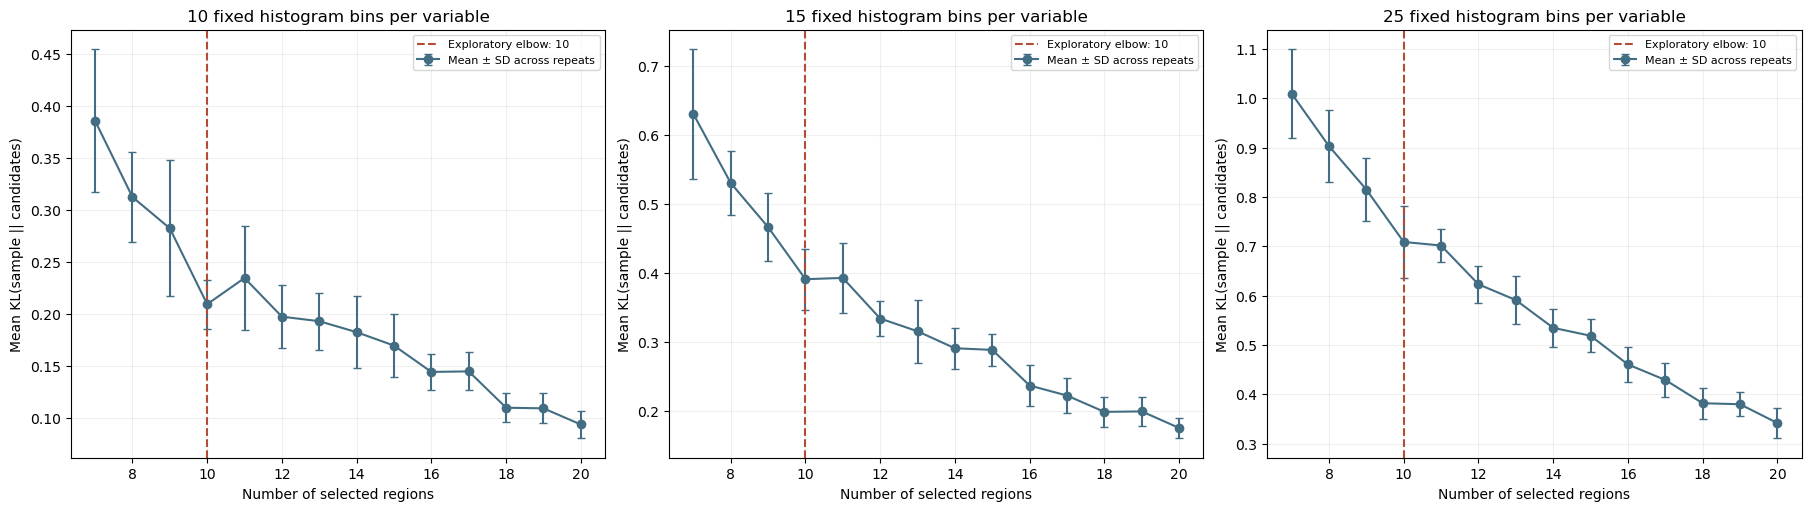

10 histogram bins: elbow at 10 regions; BIC improvement = 20.56
15 histogram bins: elbow at 10 regions; BIC improvement = 26.63
25 histogram bins: elbow at 10 regions; BIC improvement = 24.96


In [90]:
import matplotlib.pyplot as plt

kl_figure = plot_kl_exploration(selection_dir)
display(kl_figure)
plt.close(kl_figure)

elbows = json.loads((Path(selection_dir) / "elbow_diagnostics.json").read_text())
for bins, result in elbows.items():
    if result.get("n") is None:
        print(f"{bins} histogram bins: no elbow — {result.get('reason', '')}")
    else:
        print(f"{bins} histogram bins: elbow at {result['n']} regions; "
              f"BIC improvement = {result['bic_improvement']:.2f}")

In [91]:
REPORT_SAMPLE_SIZES = [10]  # Choose after inspecting Cell B.
# None = every completed size; [] = KL overview only.
available_sizes = pd.read_csv(Path(selection_dir) / "sample_size_summary.csv").n_sites
config["diagnostics"]["sample_sizes"] = report_sample_sizes(
    REPORT_SAMPLE_SIZES, available_sizes
)
print("Detailed report sections:", config["diagnostics"]["sample_sizes"])

Detailed report sections: [10]


In [92]:
diagnostic_dir = diagnose(config, candidate_dir, selection_dir)
print("Report:", diagnostic_dir / "report.html")

[17:14:51] Saved quantile maps and diagnostics for 10 sites
Report: ../../scratch/climate_site_selection/regional_site_selection/candidates_5d7de32479ad6485/selection_98a1e91b49531297/diagnostics_259199741aa82a8c/report.html


## 7. Inspect a chosen sample size

Change `SHOW_N` to a size included in `SAMPLE_SIZES`. The table includes exact download/analysis boundaries and canopy distribution. Similar-climate relationships are pairwise and need not form distinct, internally uniform groups.

,site_id,candidate_id,west,south,east,north,tree_canopy_cover_2020,canopy_fraction,usable_fraction
0,S01,C003753,106.2,59.3,113.8,63.0,42.740560,1.000000,1.000000
1,S02,C002786,116.1,54.8,122.8,58.5,32.519269,0.975986,0.975986
2,S03,C001325,-71.9,49.4,-66.1,53.1,49.130155,0.969187,0.968229
3,S04,C004062,21.7,61.1,29.7,64.8,54.650136,0.925856,0.923568
4,S05,C002457,-75.2,53.9,-68.7,57.6,28.510806,0.907732,0.907732
5,S06,C004475,-152.7,63.8,-143.9,67.5,42.140175,0.952001,0.952001
6,S07,C003156,56.7,56.6,63.7,60.3,60.479766,0.933561,0.933561
7,S08,C002647,-111.3,54.8,-104.7,58.5,51.661586,0.999168,0.999168
8,S09,C003764,126.7,59.3,134.3,63.0,38.793068,0.999657,0.999657
9,S10,C003369,88.2,57.5,95.3,61.2,63.234333,1.000000,1.000000


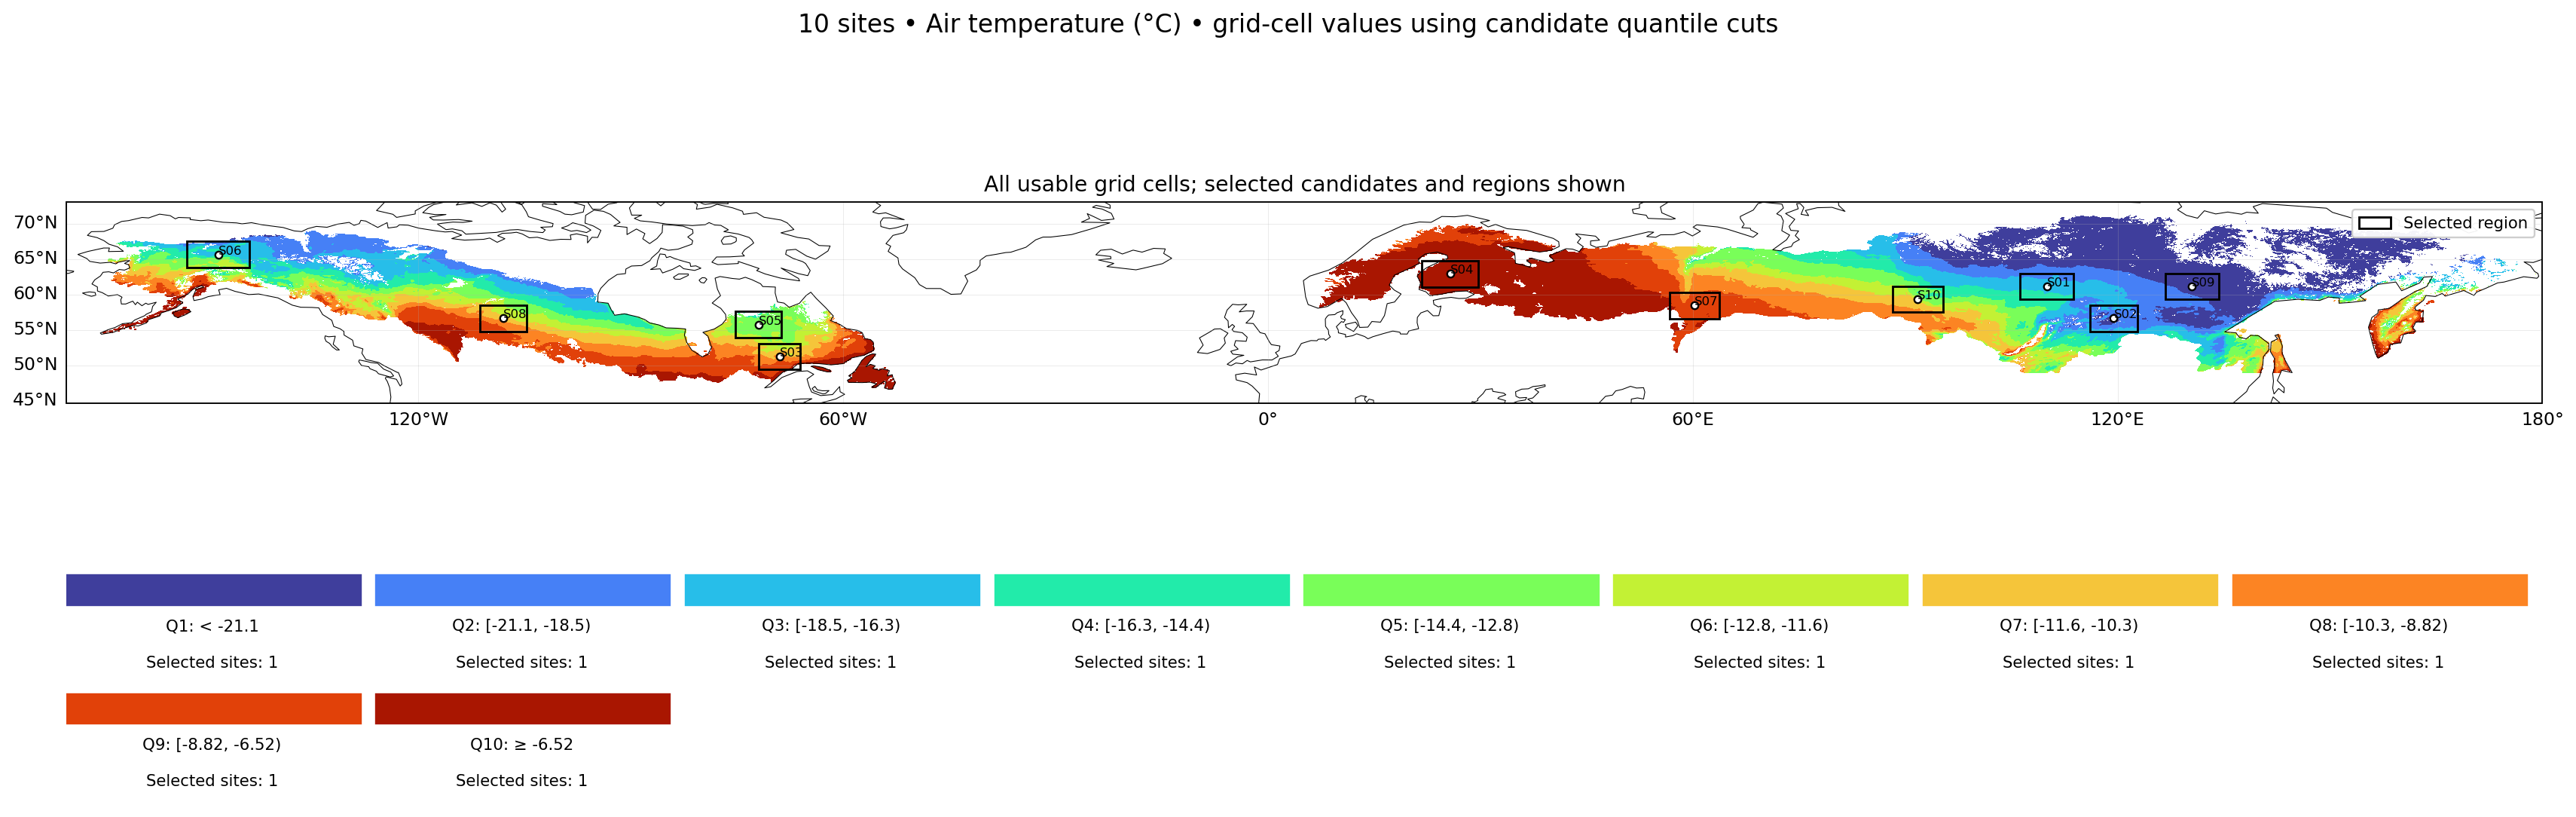

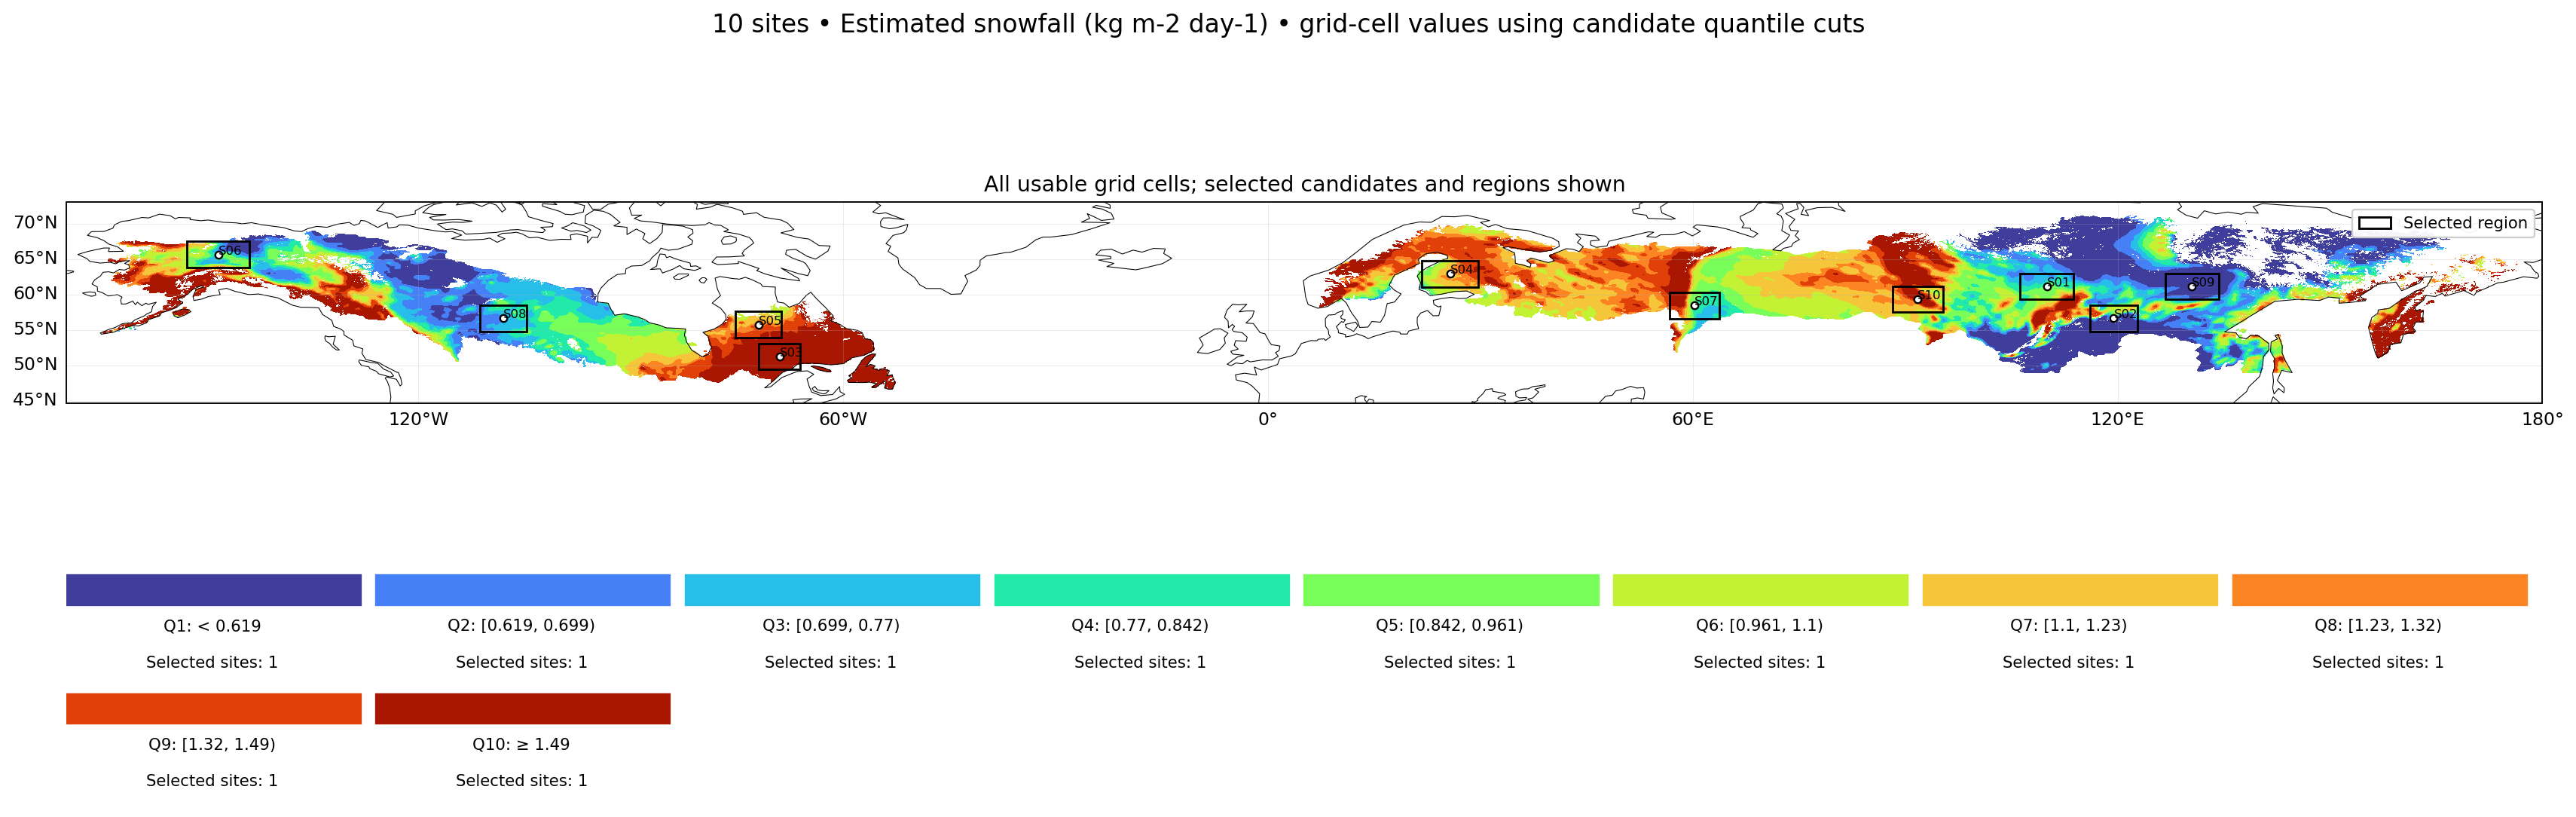

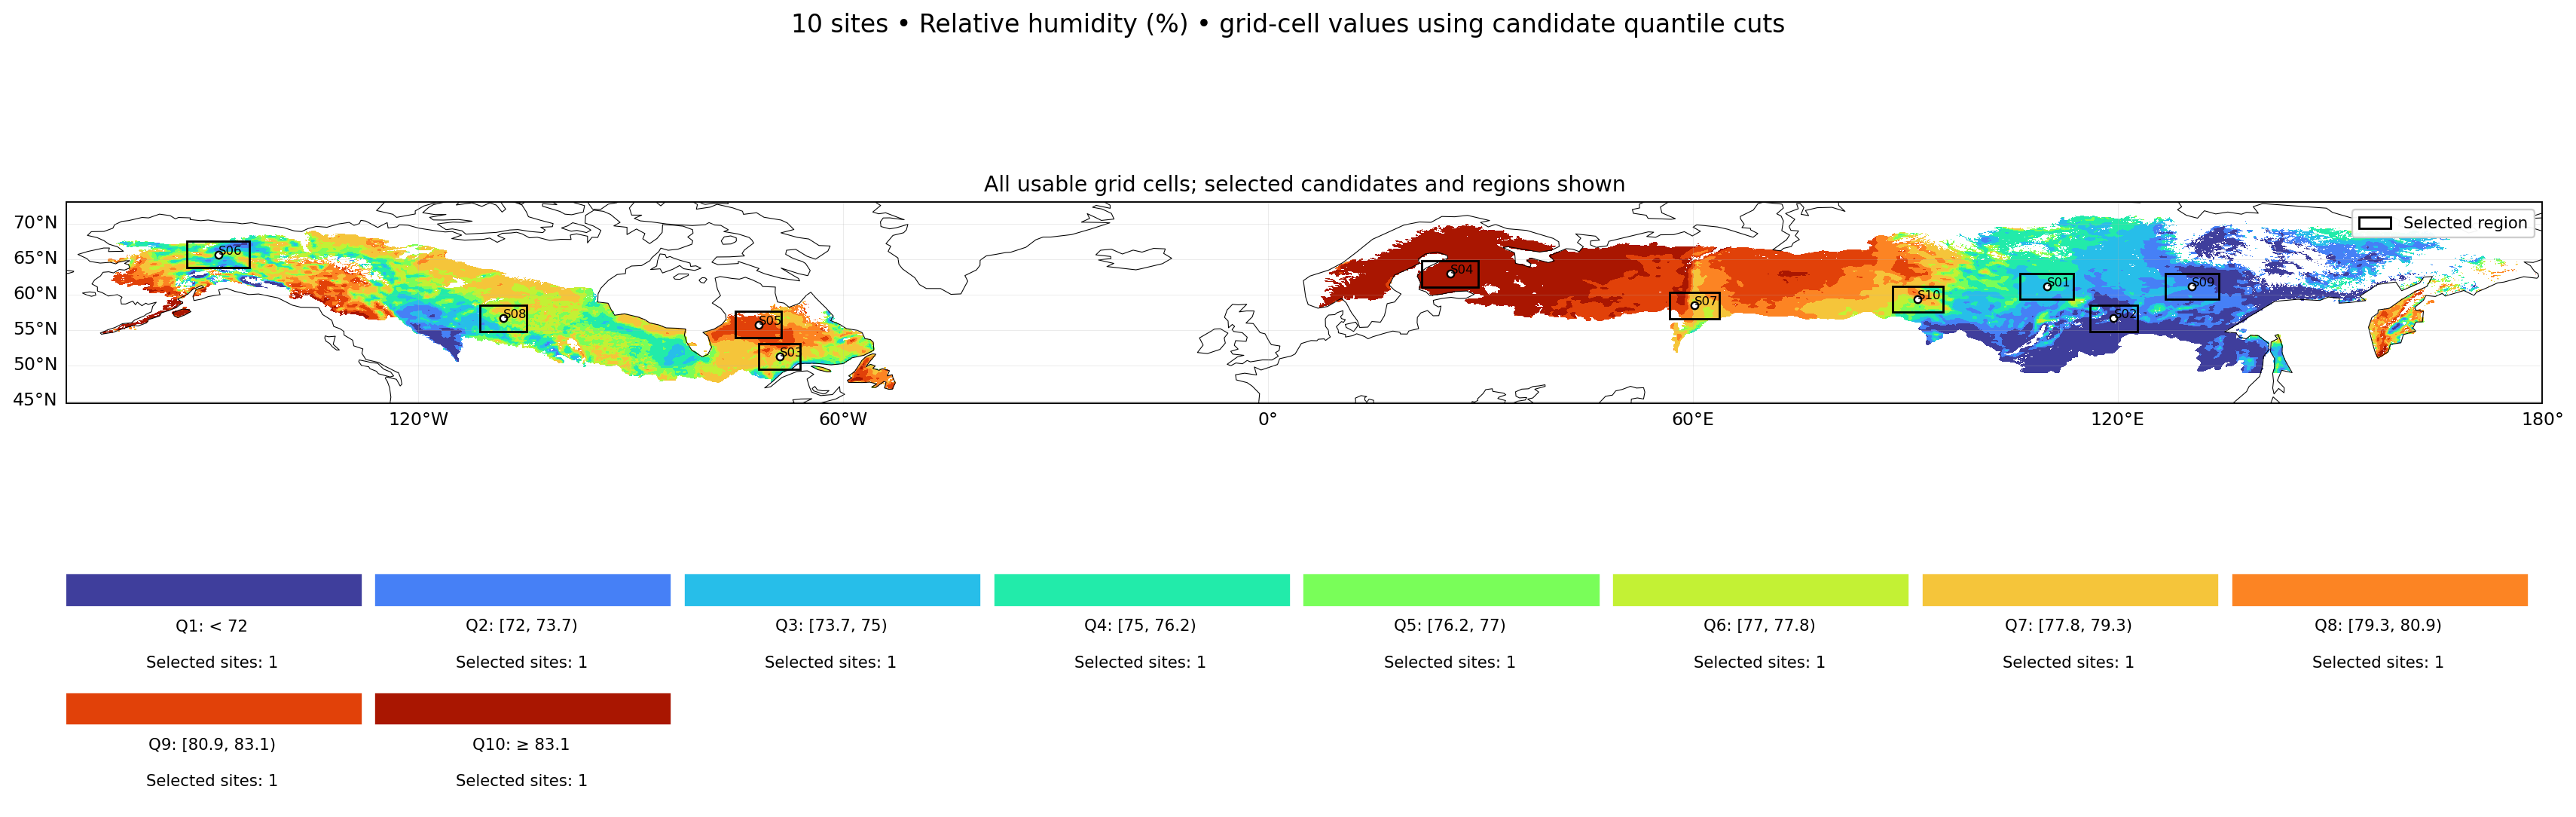

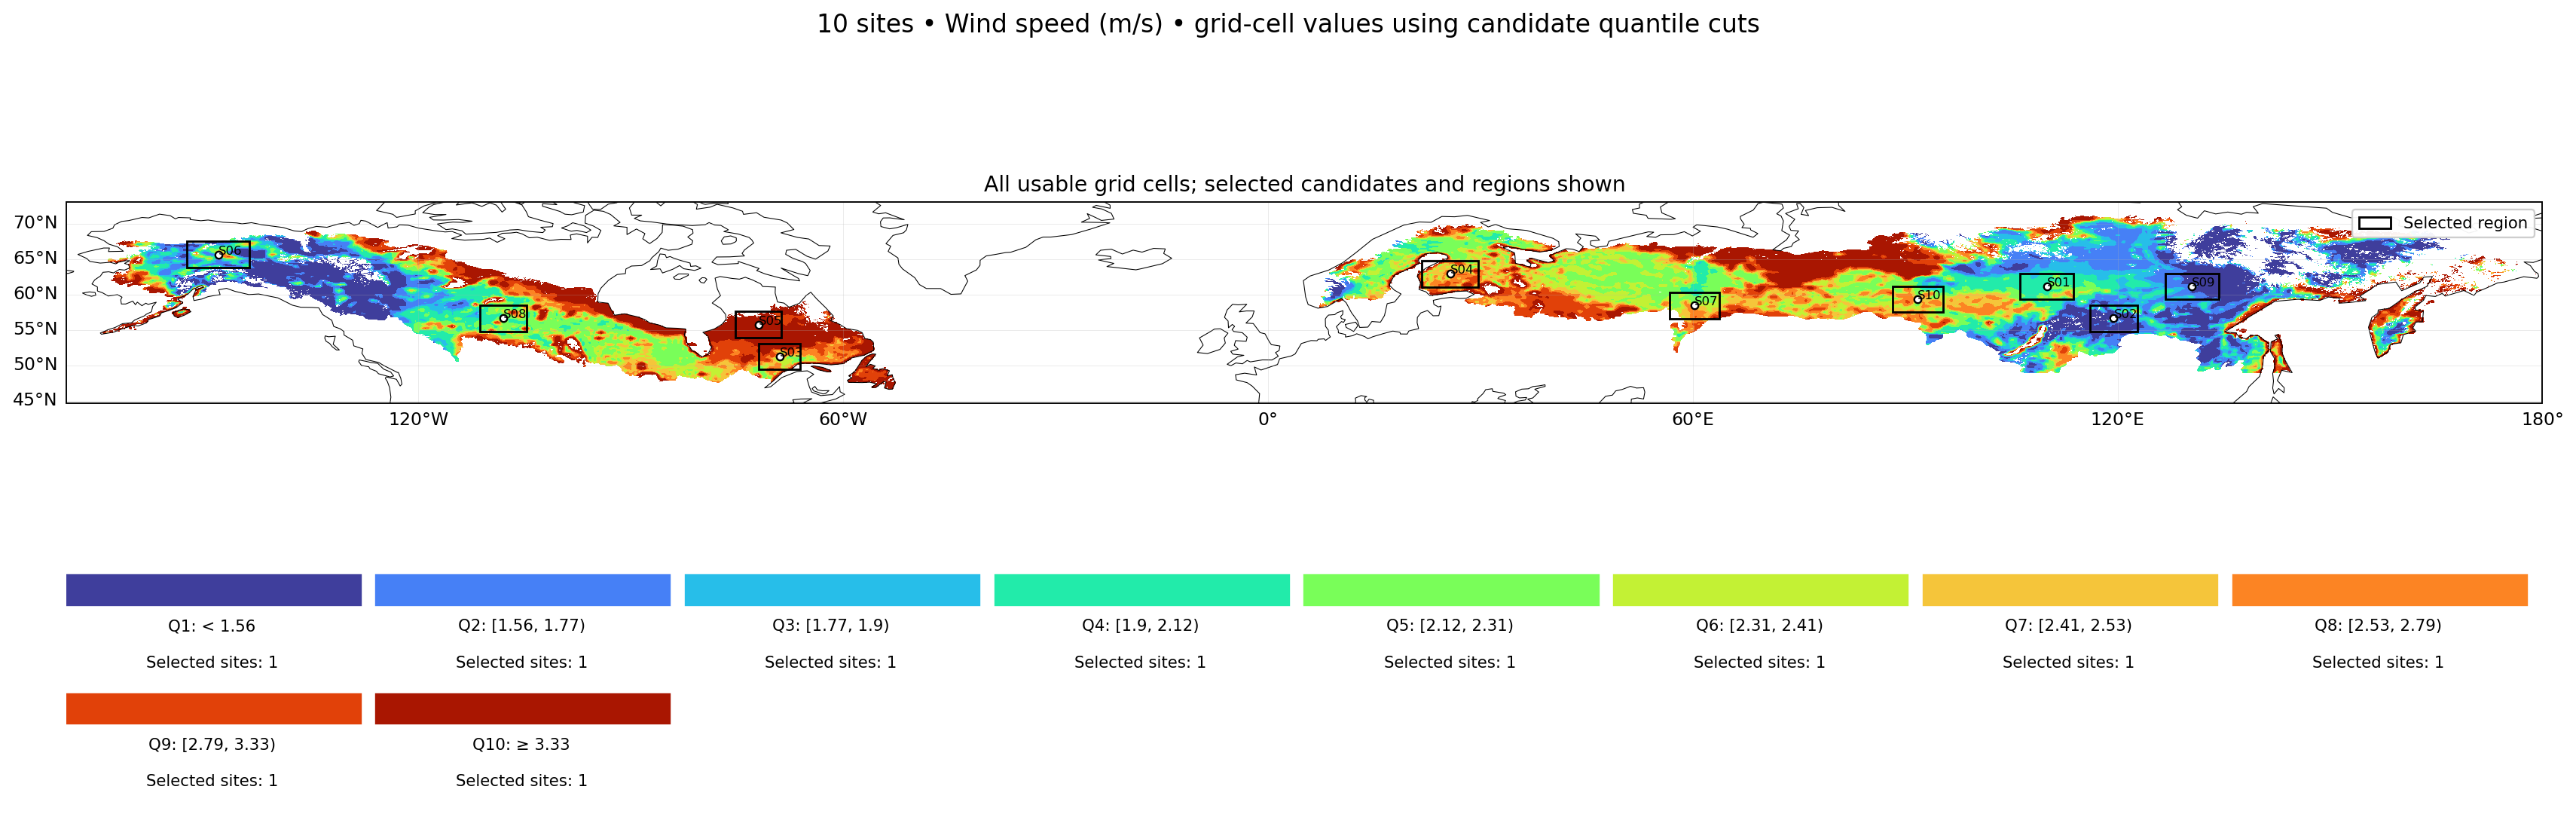

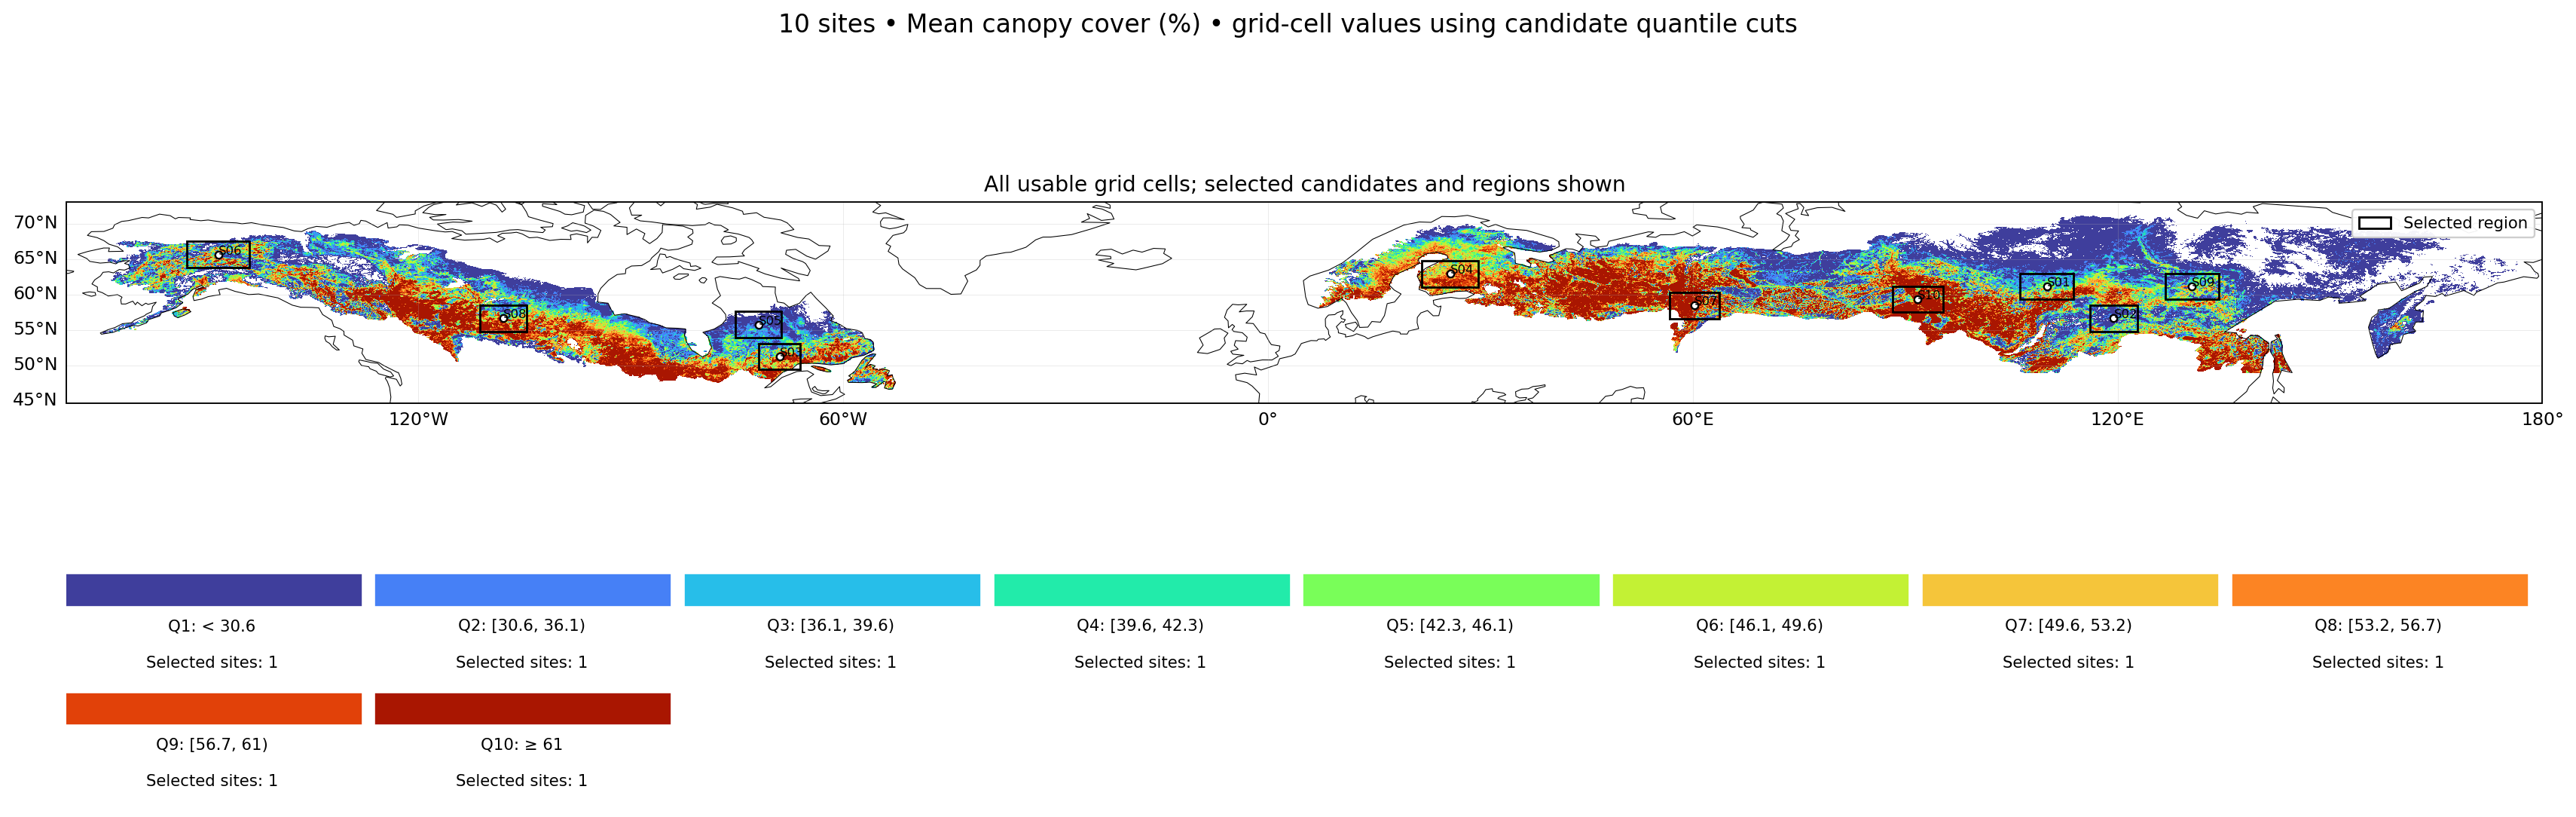

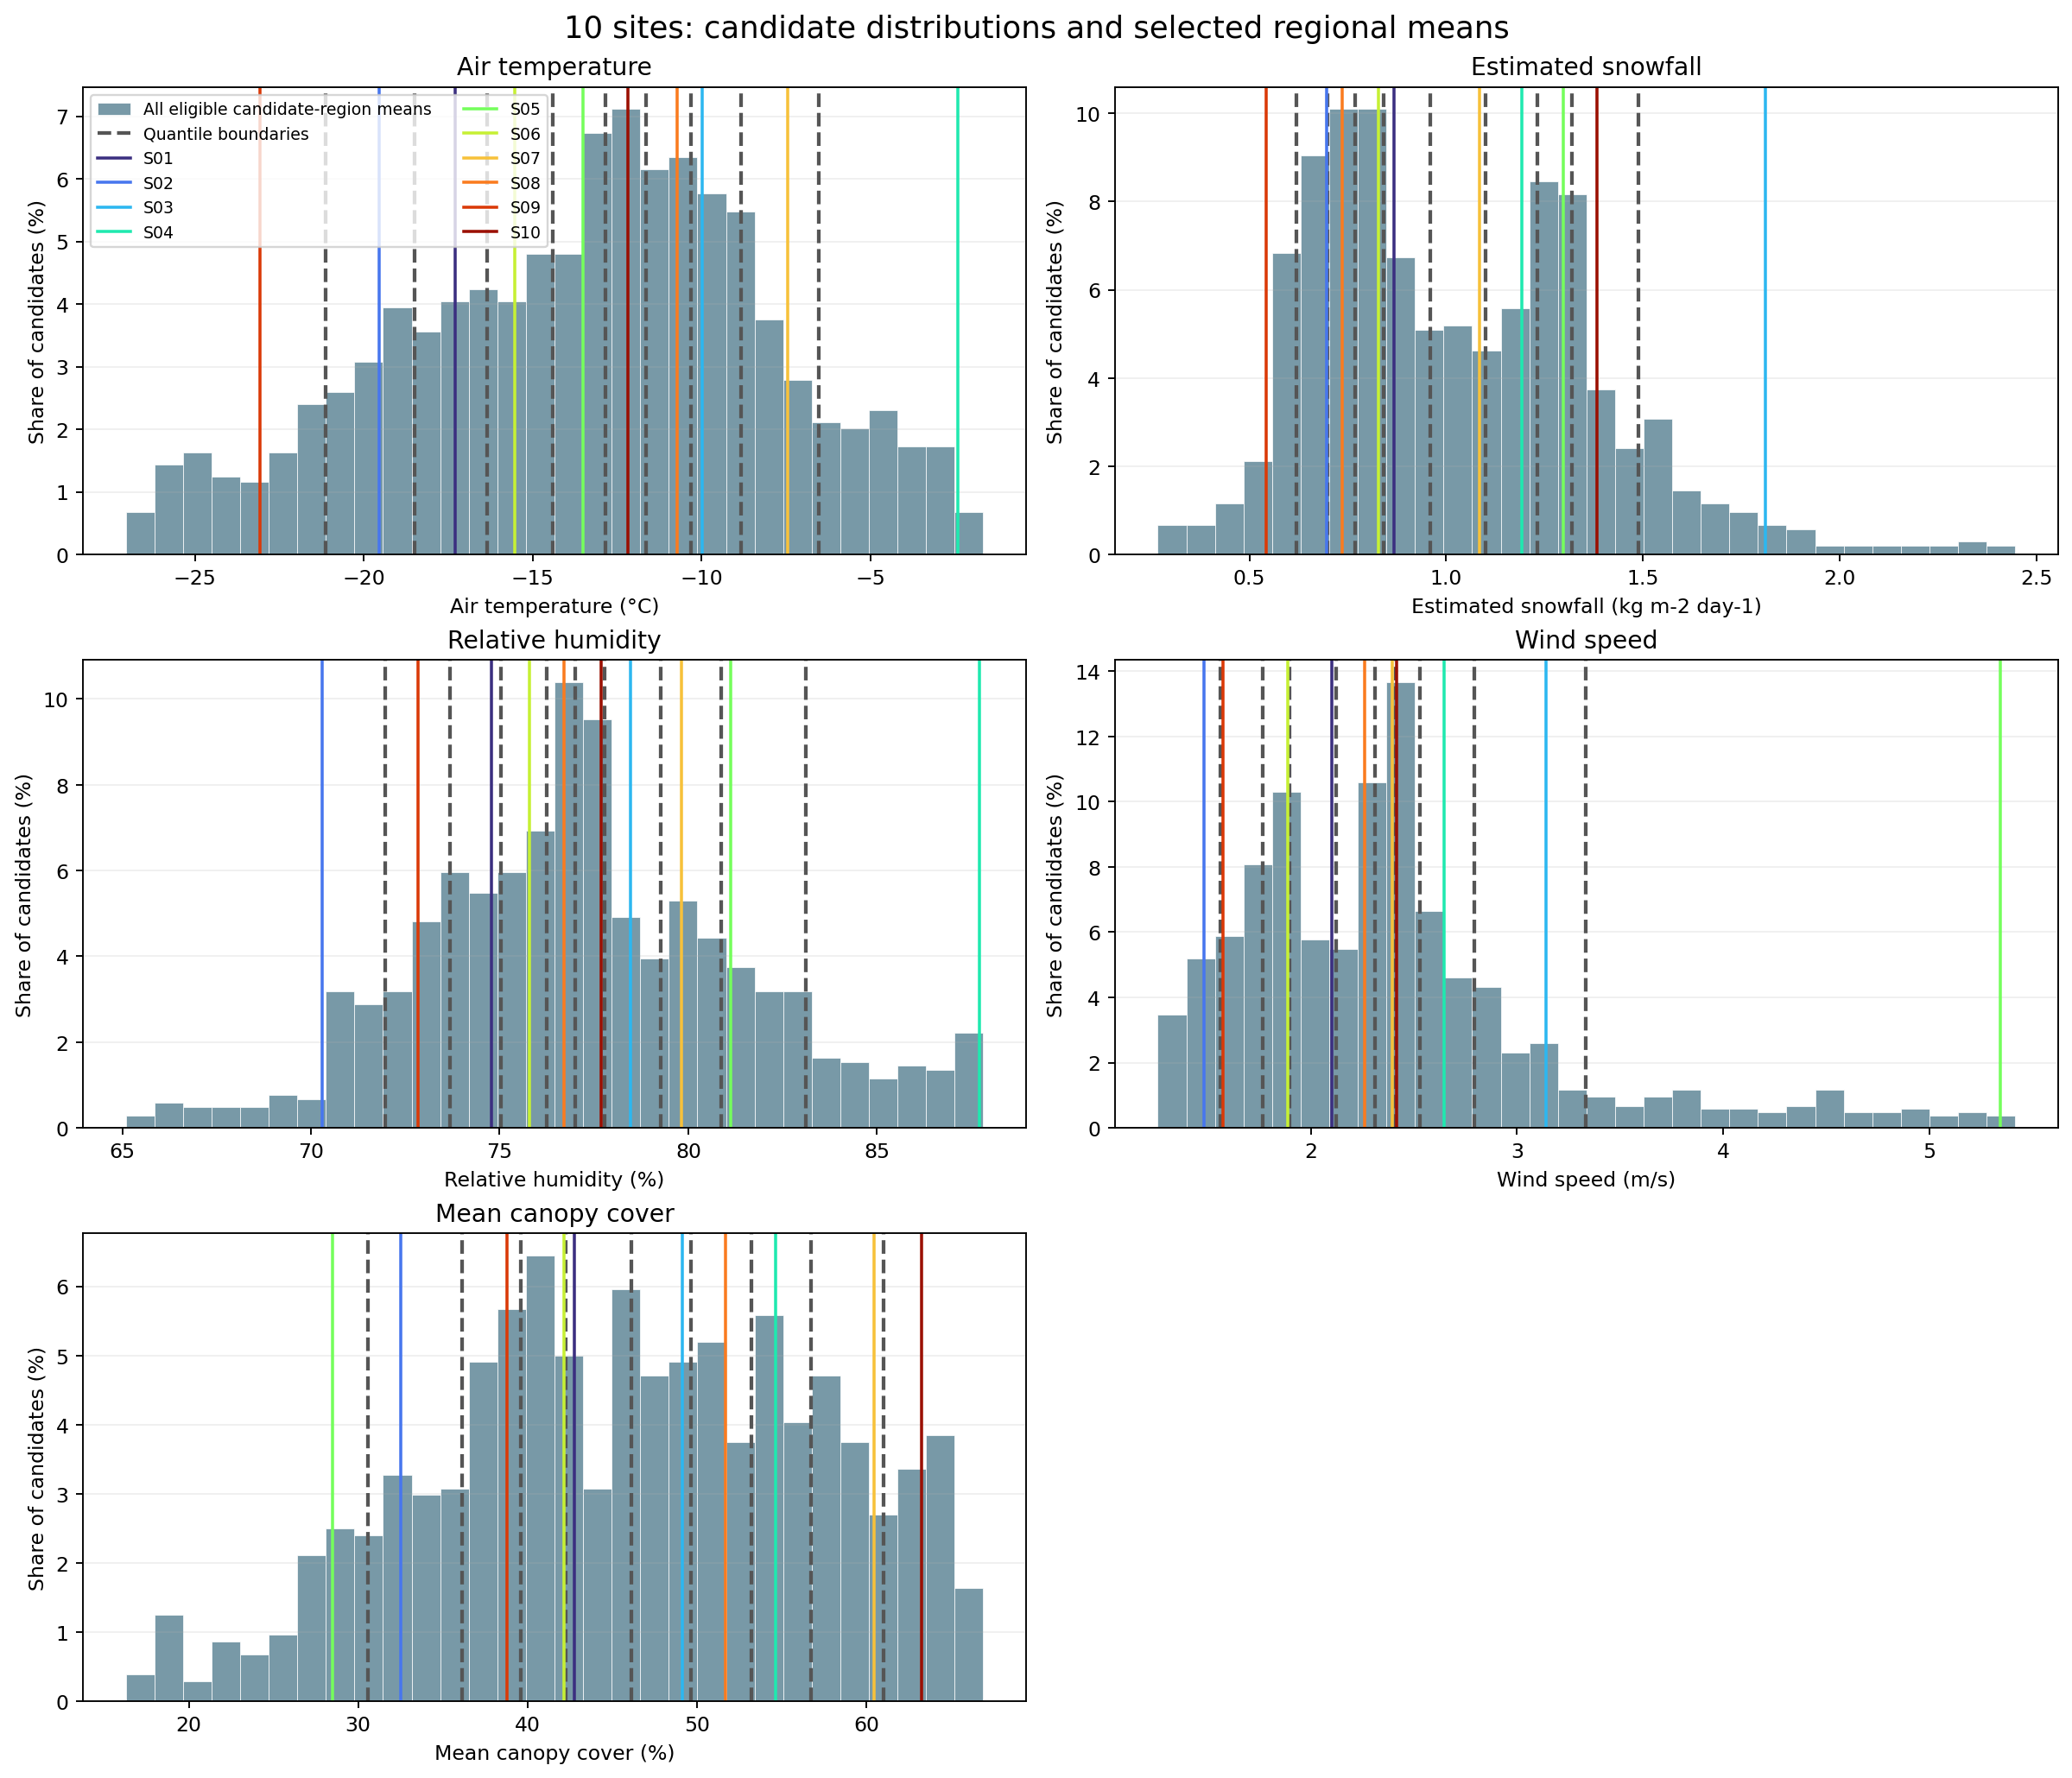

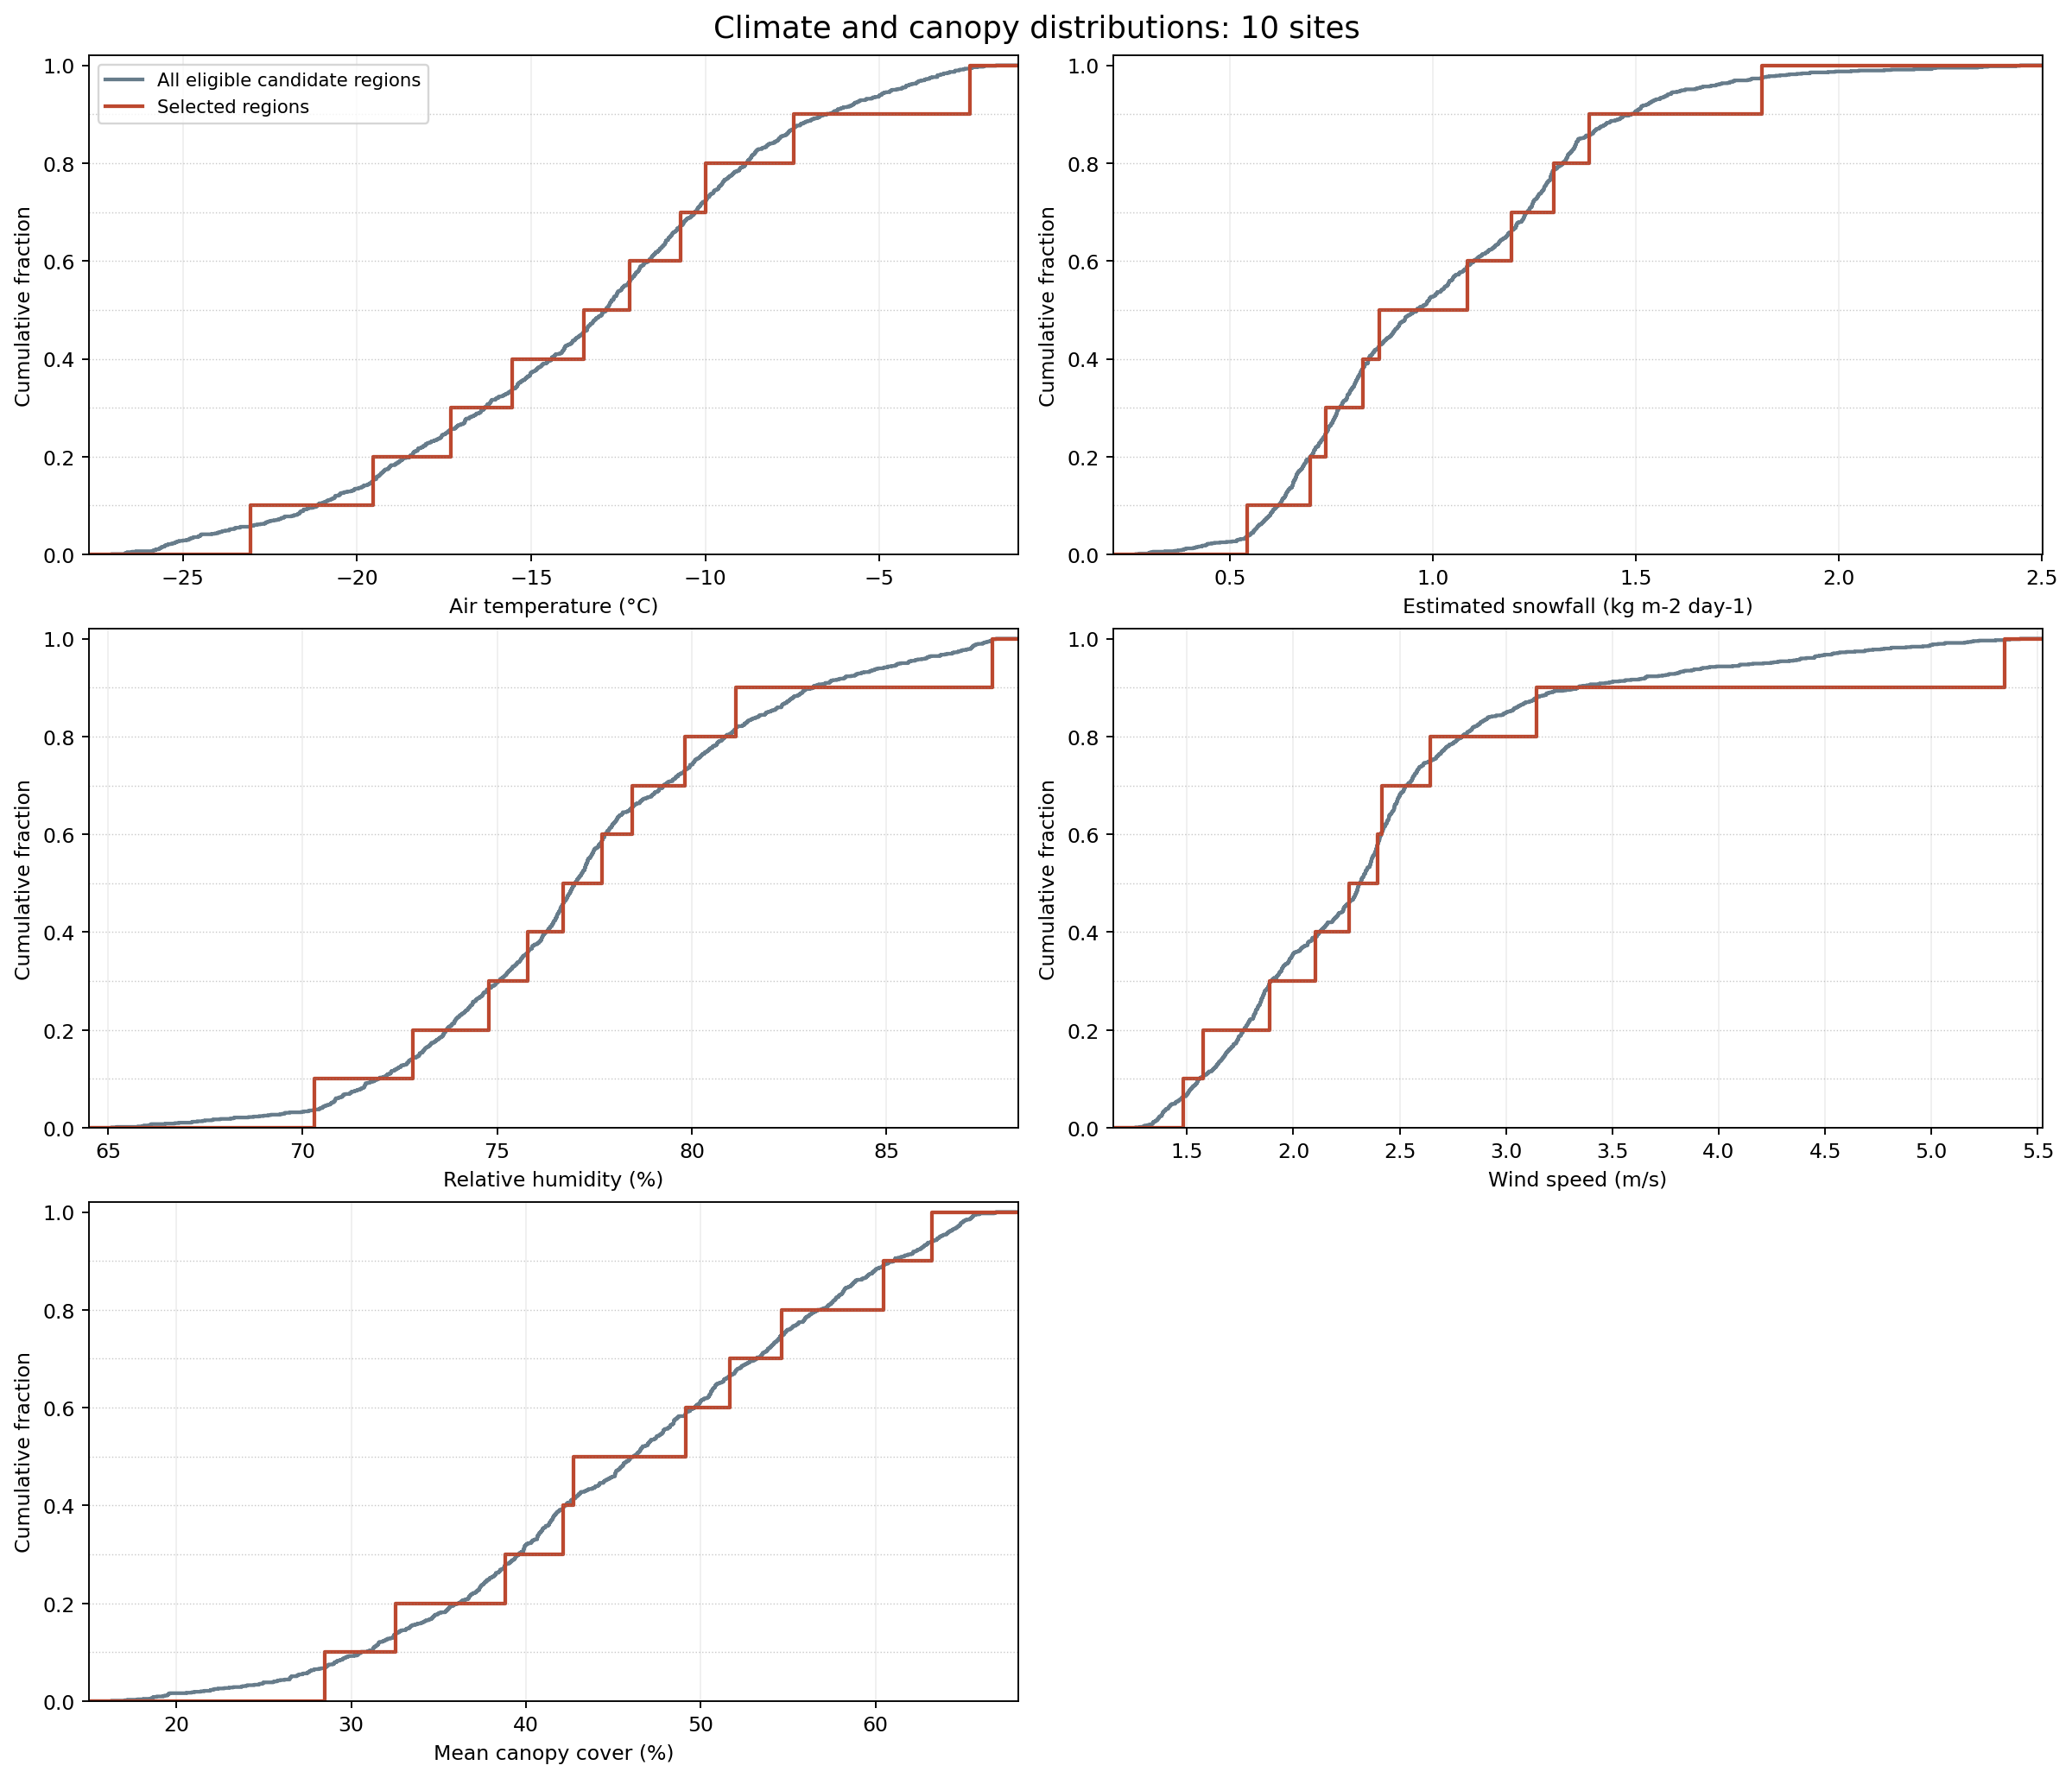

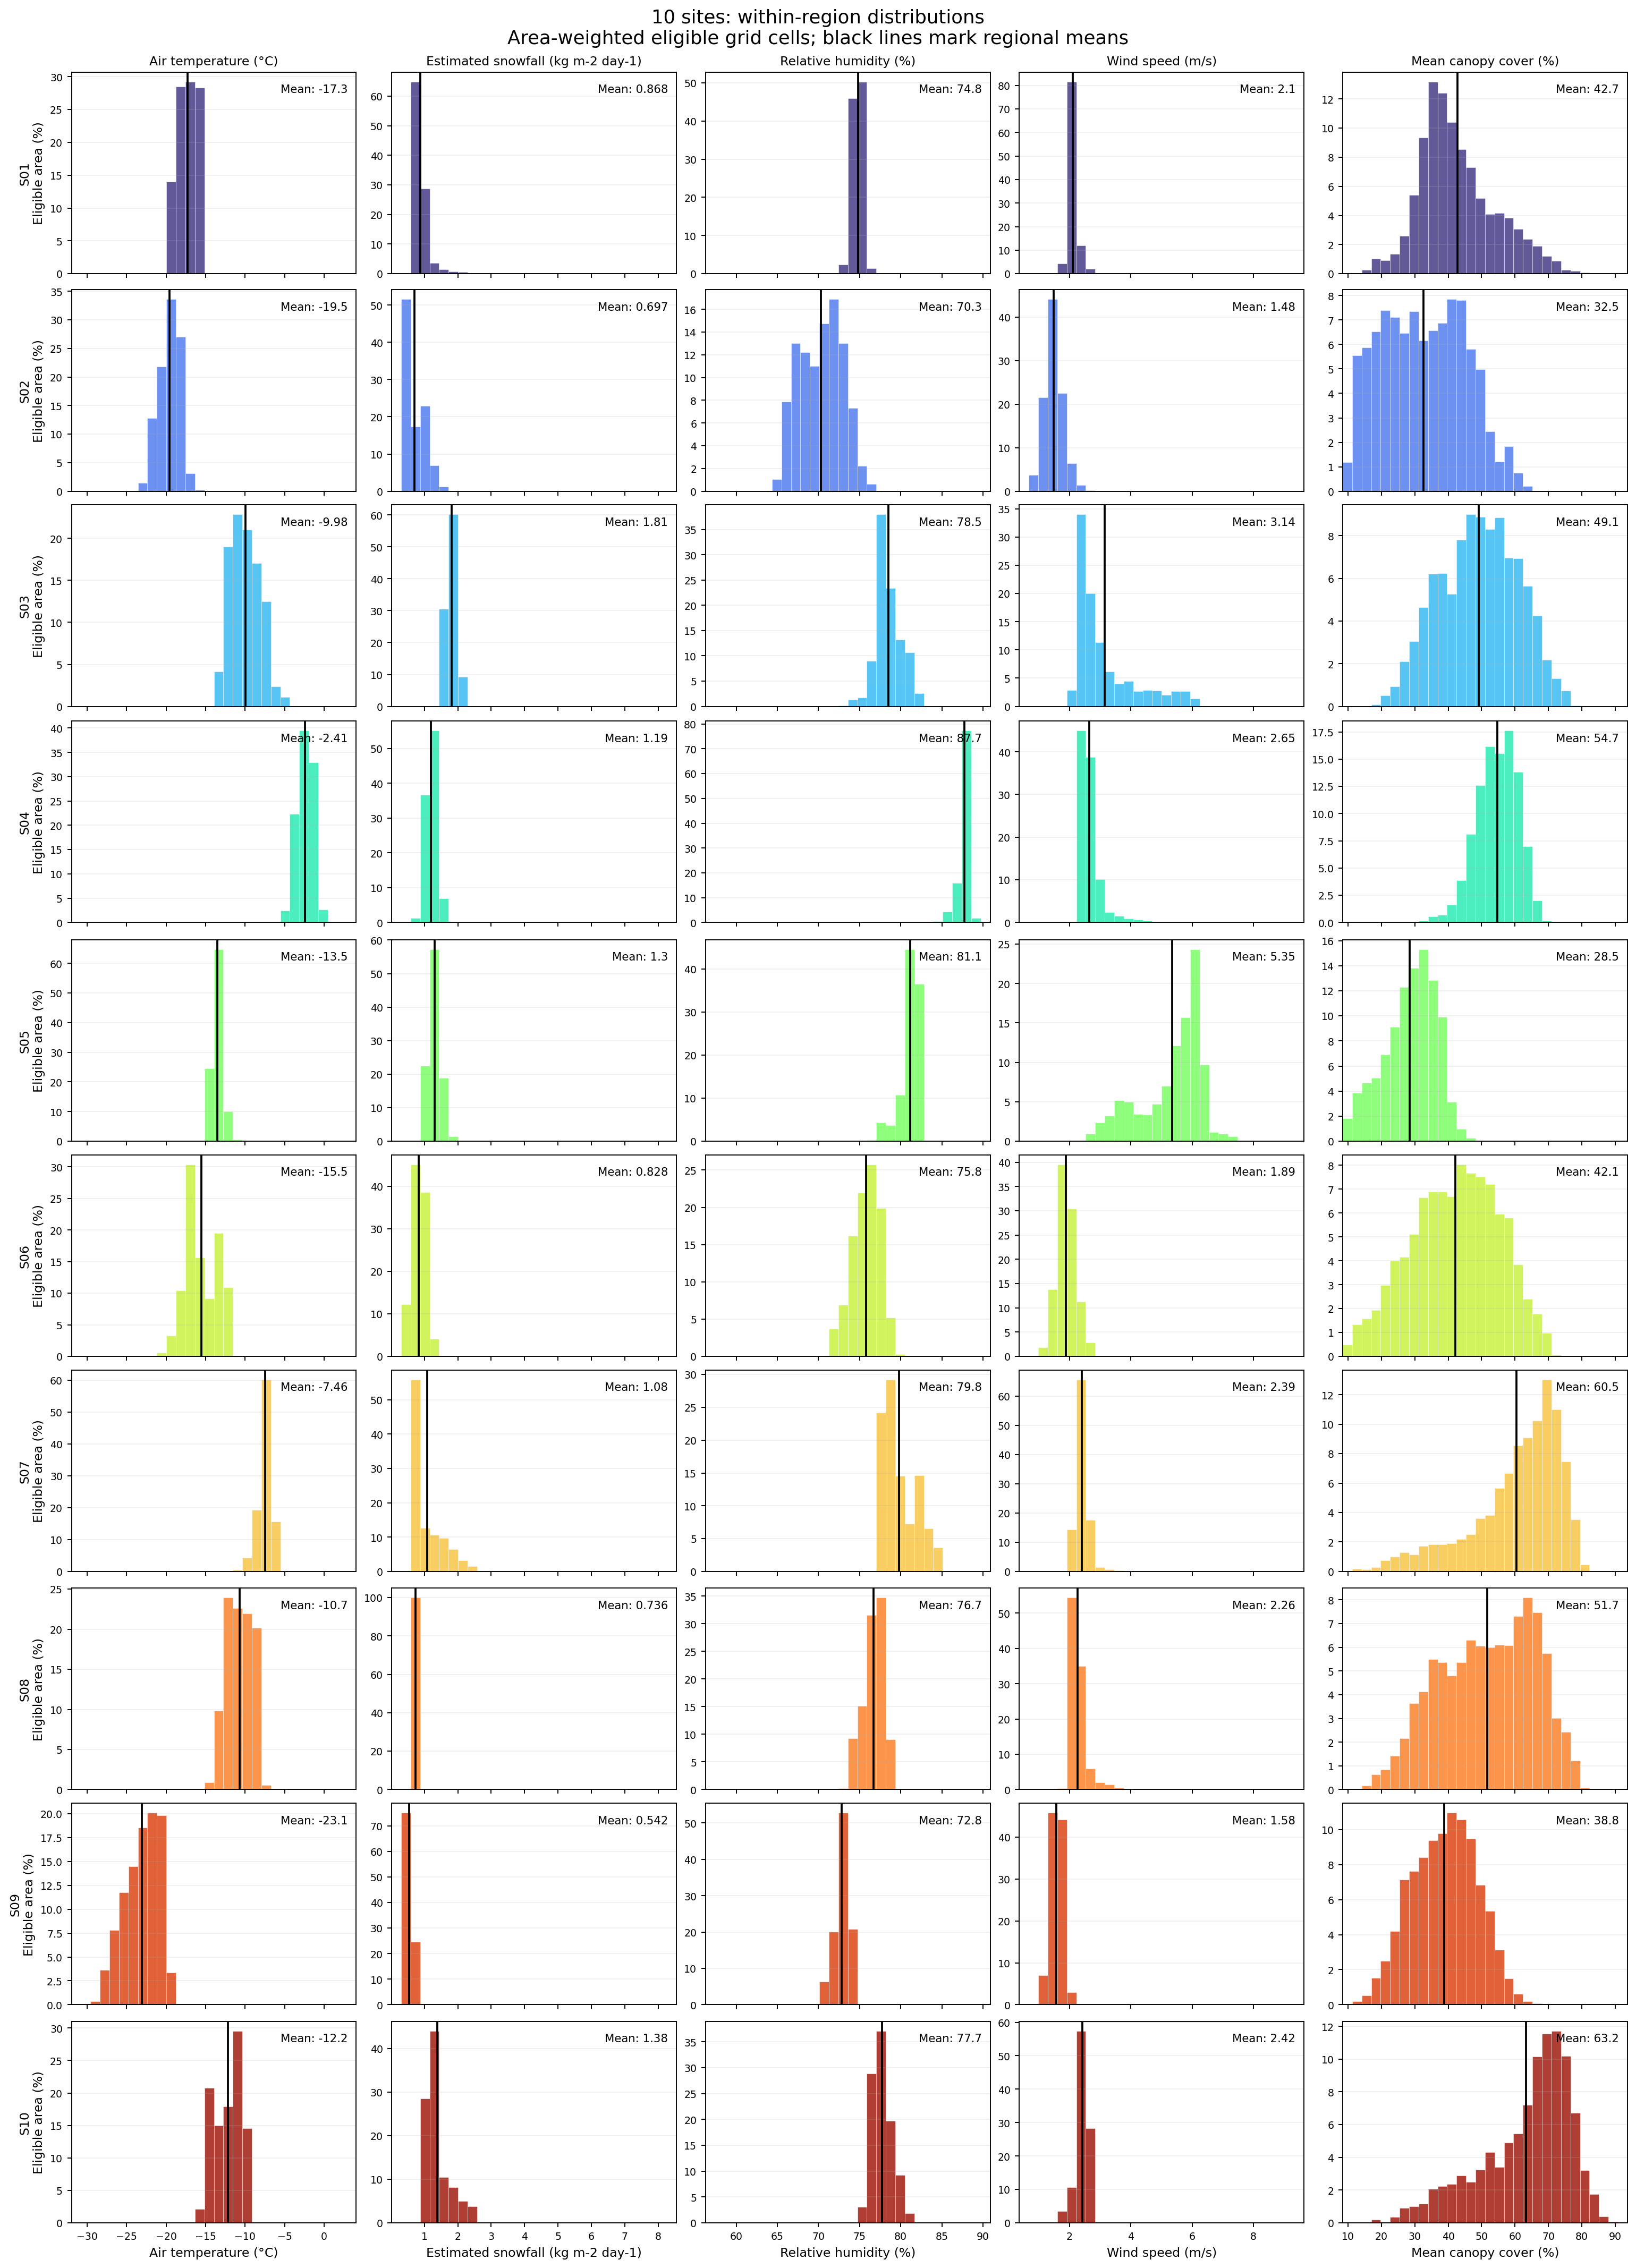

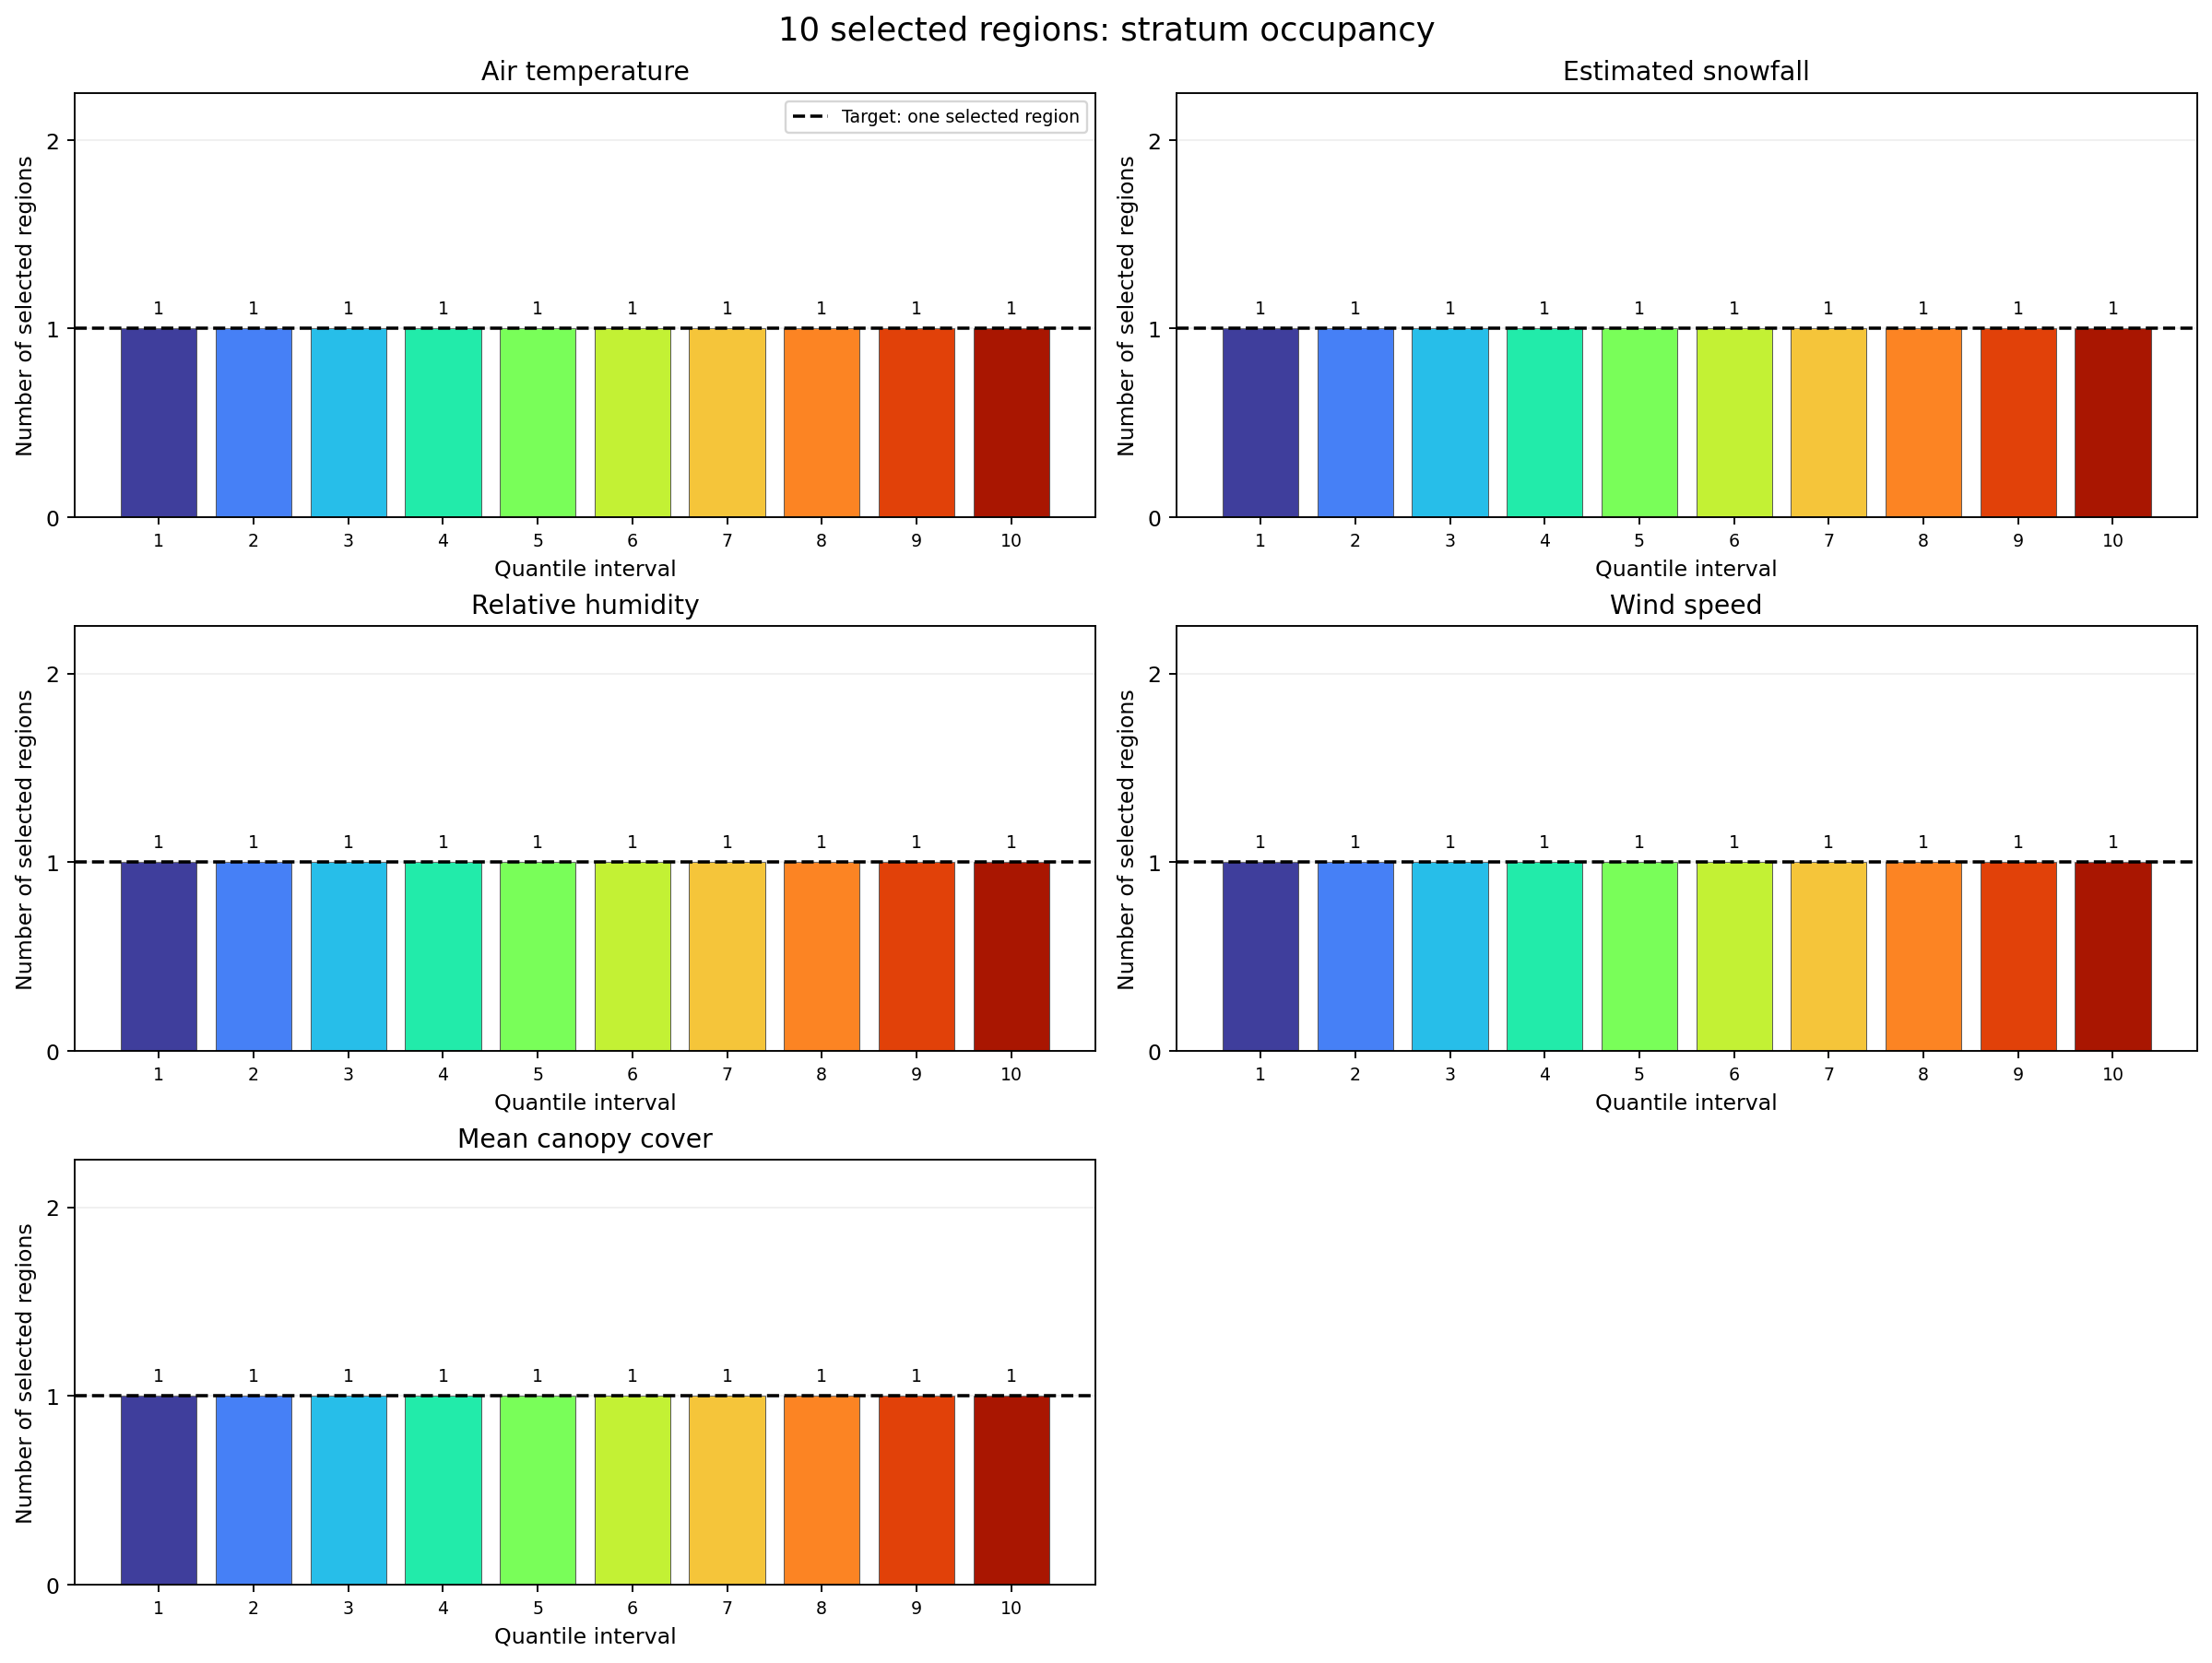

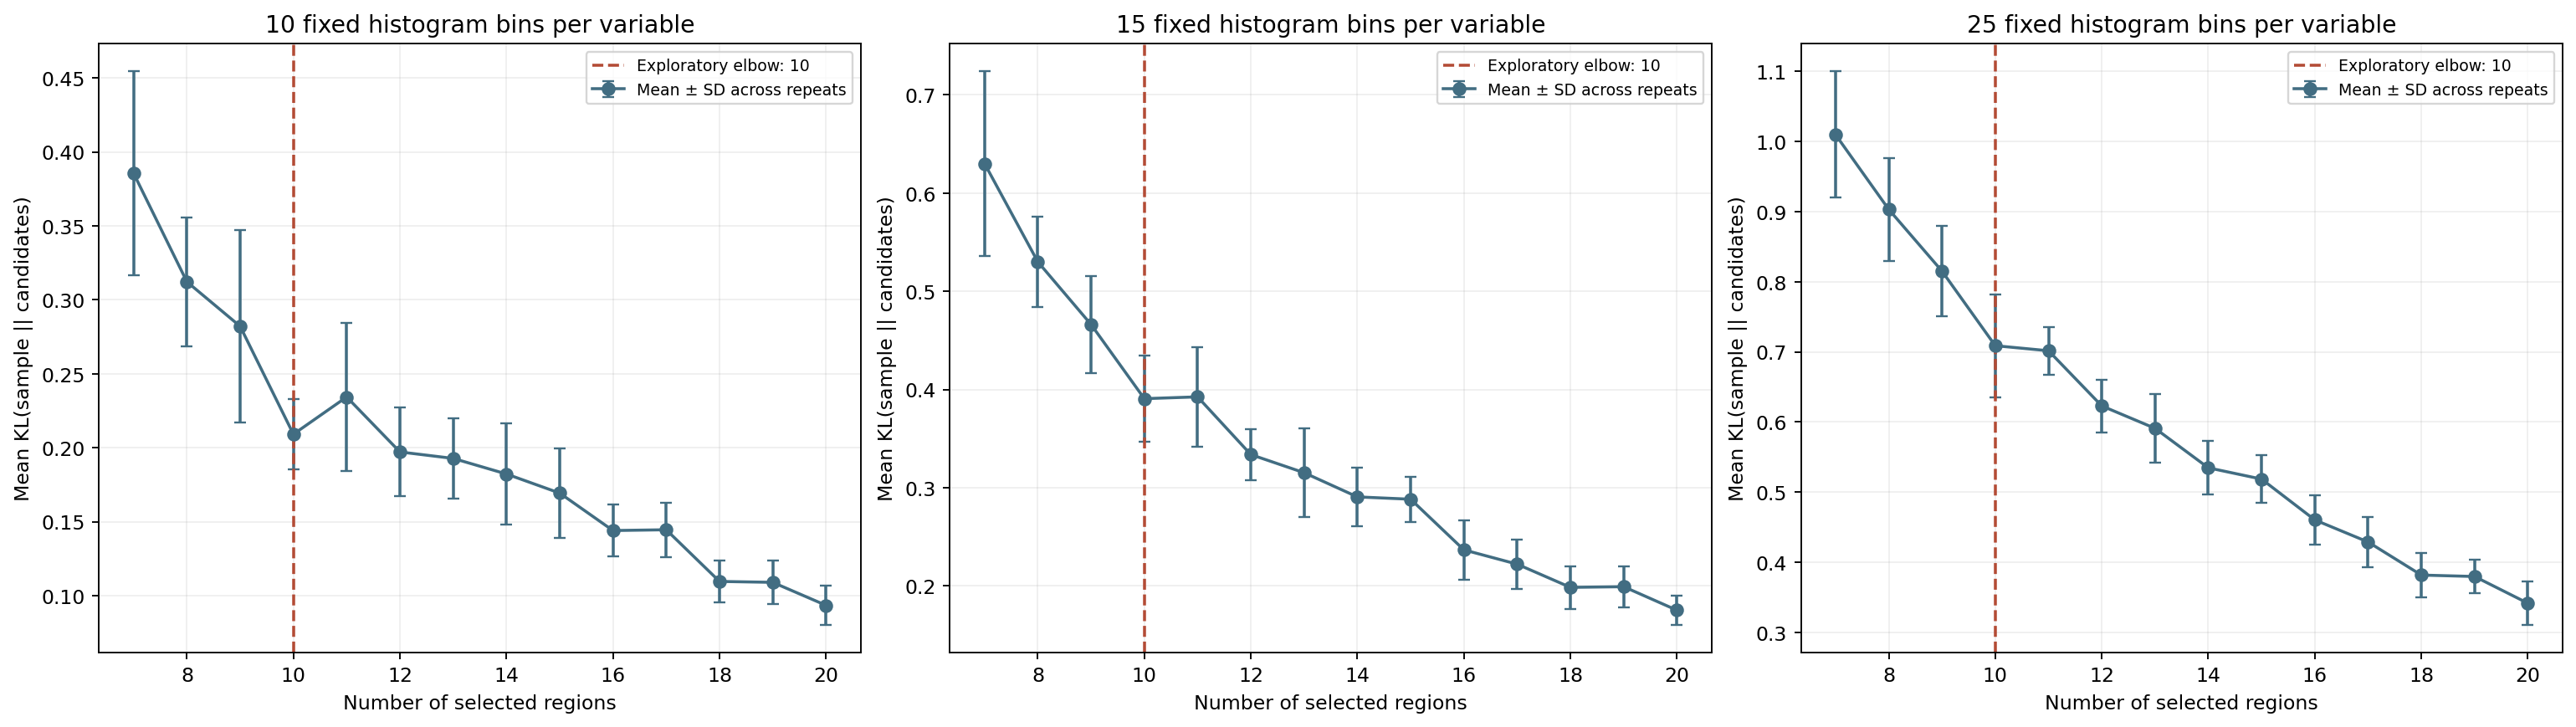

In [93]:
SHOW_N = 10  # Must also be included in REPORT_SAMPLE_SIZES (unless it is None).
requested = report_sample_sizes(
    config["diagnostics"].get("sample_sizes"),
    pd.read_csv(selection_dir / "sample_size_summary.csv").n_sites,
)
if SHOW_N not in requested:
    raise ValueError("Add SHOW_N to REPORT_SAMPLE_SIZES and regenerate the report first")
selected = pd.read_csv(selection_dir / f"n{SHOW_N:02d}" / "selected_sites.csv")
display(selected[["site_id", "candidate_id", "west", "south", "east", "north",
                  "tree_canopy_cover_2020", "canopy_fraction", "usable_fraction"]])
active = json.loads((selection_dir / f"n{SHOW_N:02d}" / "design.json").read_text())["active_variables"]
for name in active:
    display(Image(filename=str(diagnostic_dir / f"n{SHOW_N:02d}_quantiles_{name}.png")))
for suffix in ["population_histograms", "cumulative_distributions", "within_region_distributions", "stratum_occupancy"]:
    display(Image(filename=str(diagnostic_dir / f"n{SHOW_N:02d}_{suffix}.png")))
display(Image(filename=str(diagnostic_dir / "sample_size_comparison.png")))